# Butina clustering & MCES network

This notebook clusters a subset of 19,994 molecules from the Kretschmer et al (2025) MCES dataset using Butina clustering, and \
quantifies leakage betwen clusters. Leakage is defined as molecules having an $MCES^w$ < 10 and a normalized $MCES^w$ of < 0.05. 

The major steps of the pipeline are as follows:
- Load the MCES data
- Generate 1024-bit ECFP4 fingerprints for all molecules
- Cluster using Butina at thresholds from 0.4 to 0.8 inclusive
- Define a master pair dataframe containing elligible pairs for leakage as above. This is independent of cluser assignments
- Use the master pair dataframe to compute summary statistics for leakage and physicochemical properties across thresholds
- Plot figures

The only change you should need to make is to the PATH variable below.

## Imports 

In [57]:
from pathlib import Path
import os
from io import BytesIO
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator, LogLocator, LogFormatterMathtext, NullLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import to_hex
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm
import networkx as nx

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator, Descriptors, Crippen, Lipinski, rdMolDescriptors
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.ML.Cluster import Butina


## Settings

Settings for ECFP4 fingerprint generation, Butina clustering, and MCES thresholds

In [ ]:
# File path for the mces distances npz file.
PATH =  '/path/to/mces_distances.npz'

In [58]:
# Butina thresholds to use for the plot
BUTINA_THRESHOLDS = np.array([0.4, 0.5, 0.6, 0.7, 0.8], dtype=float)

# Use a Tanimoto similarity cutoff of 0.4 for the network plot.
PLOT_THRESHOLD     = 0.4

# Standard 1024-bit ECFP4 fingerprint settings.
FINGERPRINT_RADIUS = 2
FINGERPRINT_BITS   = 1024

# We use reordering to ensure better quality clustering.
BUTINA_REORDERING  = True

# Maximum MCES and MCES norm to qualify as close.
MAX_MCES           = 9
MAX_MCES_NORM      = 0.05

# Restrict clusters to be non-singletons
MIN_CLUSTER_SIZE   = 2

## Plot settings

Settings for the final figure plot

In [ ]:
# Output directory for plots and data
OUTPUT_DIR         = os.environ.get('BUTINA_OUTPUT_DIR', 'butina_network_outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [ ]:
threshold_tag = f'{PLOT_THRESHOLD:.2f}'.replace('.', 'p')
MASTER_PAIR_CSV_FILE    = os.path.join(OUTPUT_DIR, 'all_valid_mces_pairs_master.csv')

THRESHOLD_PAIR_CSV_FILE = os.path.join(
    OUTPUT_DIR, f'mces_pairs_threshold_{threshold_tag}.csv',
)

TANIMOTO_SAMPLE_PAIRS = 500000

# Selected molecule examples
chosen_candidate_ids = [15, 17, 21, 24, 26, 27, 28, 42, 68]

# Publication colours
colors = {
    '100': '#3B6EA8', 
    '010': '#6FA8B6', 
    '001': '#A7ADB2',
    '110': '#B7D3EA', 
    '101': '#7895A8', 
    '011': '#D4D9DC', 
    '111': '#1F3A5F',
}

# MCES palette
MCES_EDGE_COLOURS = {'1': '#0B2E4A', 
                     '2': '#006D77', 
                     '3': '#3B6EA8', 
                     '4': '#6FA8B6', 
                     '>=5': '#A7ADB2'
                     }

# Font sizes
AXIS_LABEL_FONTSIZE             = 22
TICK_FONTSIZE                   = 24
FRAC_TITLE_FONTSIZE             = 17
PANEL_LABEL_FONTSIZE            = 30
BUTINA_LEGEND_FONTSIZE          = 30
BUTINA_LEGEND_TITLE_FONTSIZE    = 30
BUTINA_NETWORK_TITLE_FONTSIZE   = BUTINA_LEGEND_TITLE_FONTSIZE
MCES_EDGE_LEGEND_FONTSIZE       = 30
MCES_EDGE_LEGEND_TITLE_FONTSIZE = 35
MOLECULE_EXAMPLE_LABEL_FONTSIZE = 96
MOLECULE_EXAMPLE_LABEL_BAND_PX  = 150

# Network geometry
NETWORK_SEED           = 7
MAIN_COMPONENT_RADIUS  = 0.46
SATELLITE_INNER_RADIUS = 0.51
SATELLITE_OUTER_RADIUS = 0.69
ISOLATE_INNER_RADIUS   = 0.74
ISOLATE_OUTER_RADIUS   = 0.93
SPRING_ITERATIONS      = 500
SPRING_K_SCALE         = 2.2

# Node styling
ISOLATED_NODE_COLOUR = '#A7ADB2'
ISOLATED_NODE_ALPHA  = 0.52
NODE_AREA_MIN        = 16
NODE_AREA_MAX        = 180
ISOLATED_NODE_SIZE_MULTIPLIER = 0.78
ISOLATED_NODE_MIN_DRAW_AREA   = 11

# Legend marker sizes
MCES_LEGEND_MARKERSIZE = 8

# Larger "no edge" legend circle
NO_EDGE_LEGEND_MARKERSIZE = 12

# Edge styling
NETWORK_EDGE_LINEWIDTH  = 1.75
NETWORK_EDGE_ALPHA      = 0.64

# Main layout positioning
NETWORK_SUMMARY_X = -0.08

# Butina network title/table
NETWORK_SUMMARY_SHIFT_UP_PX = 5

# MCES legend positioning
MCES_LEGEND_TITLE_X = 0.855  
MCES_LEGEND_TITLE_Y = 1.105

# Width of the blue rule beneath d_MCES^w
MCES_LEGEND_RULE_WIDTH = 0.165

# Vertical distance from title anchor to blue rule
MCES_LEGEND_RULE_DROP = 0.045

# Vertical position of legend entries relative to title
MCES_LEGEND_ENTRIES_DROP = 0.045

# Molecule column
MOLECULE_PANEL_LEFT_BASE = 0.72

# Shift molecule examples left ~10 px
MOLECULE_PANEL_SHIFT_LEFT_PX = 10
MOLECULE_PANEL_RIGHT         = 0.985
MOLECULE_PANEL_BOTTOM        = 0.072
MOLECULE_PANEL_HEIGHT        = 0.895

# Panel n
N_LABEL_BASE_X = 0.706

# Current total shift to the right
N_LABEL_SHIFT_RIGHT_PX = 30


## Loading the MCES data and selecting molecules
The MCES array uses the SciPy condensed-index convention (upper triangle, row major format). Censored pairs (`MCES == -1`) are pairs for which there is no MCES distance calculated. \
We exclude molecules that feature in one or more censored pairs so that we only use the subset of molecules for which all pairwise MCES calculations exist. 

In [ ]:
def condensed_to_pair_indices(k, n):
    """
    Convert condensed pairwise-vector indices to molecule index pairs (i, j).

    Assumes scipy.spatial.distance.pdist / squareform ordering:

        k=0       -> (0, 1)
        k=1       -> (0, 2)
        ...
        k=n-2     -> (0, n-1)
        k=n-1     -> (1, 2)
        ...
        final k   -> (n-2, n-1)

    Parameters
    ----------
    k : array-like of int
        Positions in the condensed pairwise vector.
    n : int
        Number of molecules / SMILES.

    Returns
    -------
    i, j : np.ndarray
        Arrays of molecule indices, with i < j.
    """
    k = np.asarray(k, dtype=np.int64)

    # Number of pairs in each row: n-1, n-2, ..., 1
    row_sizes = np.arange(n - 1, 0, -1)

    # Starting position of each row in the condensed vector
    row_starts = np.concatenate(([0], np.cumsum(row_sizes)))

    # Identify the row containing each index
    i = np.searchsorted(row_starts, k, side="right") - 1

    # Identify the column within that row
    j = i + 1 + (k - row_starts[i])

    return i, j

def load_mces_distances(path):
    """ Load and validate the SMILES and condensed MCES arrays."""
    path = Path(path)

    with np.load(path, allow_pickle=True) as data:
        smiles_array = np.asarray(data['smiles'])
        mces_array   = np.asarray(data['mces'])

    return (smiles_array, mces_array)

def identify_uncensored_molecules(mces_values, n_molecules):
    """ Identify molecules never featured in an MCES=-1 censored pair."""
    # Array indices of censored positions
    censored_positions    = np.flatnonzero(mces_values == -1)
    # Arrays containing the indices of molecules that are censored in the mces array
    pair_i, pair_j        = condensed_to_pair_indices(censored_positions, n_molecules)
    # Mask to censor molecules of length n_molecules
    featured_mask         = np.zeros(n_molecules, dtype=bool)
    # Censor all molecules that feature in one or more of the censored pairs
    featured_mask[pair_i] = True
    featured_mask[pair_j] = True
    return {
        'censored_positions':   censored_positions, 'pair_i': pair_i, 'pair_j': pair_j,
        'featured_mask':        featured_mask,
        'featured_indices':     np.flatnonzero(featured_mask),
        'not_featured_indices': np.flatnonzero(~featured_mask),
    }


In [ ]:
# Read data and create the uncensored subset.
smiles, mces = load_mces_distances(PATH)
distances    = {"smiles": smiles, "mces": mces}  
n            = len(smiles)

censoring    = identify_uncensored_molecules(mces, n)
censored_pos = censoring['censored_positions']

featured_in_censored_pair = censoring['featured_mask']
featured_indices          = censoring['featured_indices']
not_featured_indices      = censoring['not_featured_indices']
not_featured_smiles       = smiles[not_featured_indices]

input_summary = pd.DataFrame({
    'metric': [
        'All input molecules', 
        'Condensed pair entries', 
        'Censored pair entries',
        'Molecules in censored pairs', 
        'Molecules eligible for Butina',
    ],
    'count': [n, 
              len(mces), 
              len(censored_pos), 
              len(featured_indices), 
              len(not_featured_indices)
              ],
})
display(input_summary)


,metric,count
0,All input molecules,63437
1,Condensed pair entries,2012094766
2,Censored pair entries,772417143
3,Molecules in censored pairs,43443
4,Molecules eligible for Butina,19994


## Multi-threshold Butina clustering

Generate ECFP4 fingerprints for the 19,994 molecule subset of molecules for which MCES calculations are available and cluster them using multiple Butina thresholds.


In [ ]:
def mols_from_smiles(smiles):
    """ Parse input SMILES and return valid RDKit molecules, SMILES, and source indices."""
    mols = []
    valid_smiles = []
    valid_indices = []

    for i, smi in enumerate(smiles):
        mol = Chem.MolFromSmiles(smi)

        if mol is None:
            continue
        mols.append(mol)
        valid_smiles.append(smi)
        valid_indices.append(i)

    return (
        mols, np.array(valid_smiles),
        np.array(valid_indices, dtype=np.int64),
    )

def morgan_fingerprints(mols, radius=2, n_bits=1024):
    """ Generate ECFP4 fingerprints for every molecule with the given radius and bit count."""
    fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    return [fpgen.GetFingerprint(mol) for mol in mols]

def tanimoto_distance_vector(fps, dtype=np.float32):
    """ Build the condensed pairwise Tanimoto distance vector used by Butina clustering.
        Note that this outputs the condensed vector in lower-triangular, row-major order
        not upper triangle. 
    
    """
    n      = len(fps)
    dists  = np.empty(n * (n - 1) // 2, dtype=dtype)
    offset = 0

    for i in range(1, n):
        sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])
        dists[offset:offset + i] = 1.0 - np.asarray(sims, dtype=dtype)
        offset += i

        if i % 1000 == 0:
            print(f'Built distances for {i:,}/{n:,} molecules')

    return dists

def butina_cluster_from_distance_vector(dists, n, similarity_cutoff, reordering=True):
    """ Apply Butina clustering at one similarity cutoff and return cluster assignments and sizes."""
    distance_cutoff = 1.0 - float(similarity_cutoff)
    clusters        = Butina.ClusterData(
        dists, n, distance_cutoff, isDistData=True, reordering=reordering,
    )
    # Convert tuple of tuples to a list of tuples
    clusters       = [c for c in clusters]

    # Assign cluster labels to each molecule
    cluster_labels = np.full(n, -1, dtype=np.int64)
    for cluster_id, cluster in enumerate(clusters):
        cluster_labels[list(cluster)] = cluster_id

    # Summary statistics for clusters.
    cluster_sizes          = np.array([len(c) for c in clusters], dtype=np.int64)
    non_singleton_clusters = [c for c in clusters if len(c) > 1]
    singleton_clusters     = [c for c in clusters if len(c) == 1]

    return {
        'clusters': clusters, 
        'cluster_labels': cluster_labels,
        'cluster_sizes': cluster_sizes,
        'non_singleton_clusters': non_singleton_clusters,
        'singleton_clusters': singleton_clusters,
        'similarity_cutoff': float(similarity_cutoff),
        'distance_cutoff': float(distance_cutoff),
    }

def butina_cluster_smiles_multi_thresholds(
    smiles, 
    thresholds=np.array([0.4, 0.5, 0.6, 0.7, 0.8], dtype=float), 
    radius=2,
    n_bits=1024, 
    reordering=True,
):
    """ Calculates fingerprints once, then clusters the  
        molecules at each requested cutoff.

        Returns a dictionary containing the summary
        statistics and relevant data for each cluster
        threshold.
    """
    mols, valid_smiles, valid_indices = mols_from_smiles(smiles)
    n = len(mols)
    print(f'Input SMILES: {len(smiles):,}')
    print(f'Valid mols:   {n:,}')

    # Fingerprint using ECFP4 and then get the Tanimoto distance vector
    fps   = morgan_fingerprints(mols, radius=radius, n_bits=n_bits)
    dists = tanimoto_distance_vector(fps)
    results_by_threshold = {}

    # Cluster for each given threshold
    for threshold in thresholds:

        print(f'\nRunning Butina threshold {threshold:.2f}')
        threshold_result = butina_cluster_from_distance_vector(
            dists=dists, n=n, similarity_cutoff=threshold, reordering=reordering,
        )
        # Append the molecule objects, smiles, indices and fingerprints to the results
        threshold_result['mols']          = mols
        threshold_result['valid_smiles']  = valid_smiles
        threshold_result['valid_indices'] = valid_indices
        threshold_result['fingerprints']  = fps
        
        # Group resuts by threshold
        results_by_threshold[threshold]   = threshold_result
        cluster_sizes                     = threshold_result['cluster_sizes']

        # Print summary statistics per threshold
        print(f"Total clusters:         {len(threshold_result['clusters']):,}")
        print(f"Non-singleton clusters: {len(threshold_result['non_singleton_clusters']):,}")
        print(f"Singleton clusters:     {len(threshold_result['singleton_clusters']):,}")
        print(f'Largest cluster size:   {cluster_sizes.max():,}')

    return {
        'mols': mols, 
        'valid_smiles': valid_smiles, 
        'valid_indices': valid_indices,
        'fingerprints': fps, 
        'results_by_threshold': results_by_threshold, 
    }


In [ ]:
# Fingerprints and Tanimoto distance matrix will be reused for all cutoffs.
multi_result = butina_cluster_smiles_multi_thresholds(
    smiles=not_featured_smiles,
    thresholds=BUTINA_THRESHOLDS,
    radius=FINGERPRINT_RADIUS,
    n_bits=FINGERPRINT_BITS,
    reordering=BUTINA_REORDERING,
)

results_by_threshold = multi_result['results_by_threshold']

# Overview for all of the thresholds
clustering_overview = pd.DataFrame([{'Butina cutoff': cutoff, 
                                     'All clusters':  len(cluster_result['clusters']),
                                     'Non-singletons': len(cluster_result['non_singleton_clusters']),
                                     'Singletons':     len(cluster_result['singleton_clusters']),
                                     'Largest cluster': int(cluster_result['cluster_sizes'].max())} for cutoff,
                                     cluster_result in sorted(results_by_threshold.items())]
                                    )
display(clustering_overview)


Input SMILES: 19,994
Valid mols:   19,994
Built distances for 1,000/19,994 molecules
Built distances for 2,000/19,994 molecules
Built distances for 3,000/19,994 molecules
Built distances for 4,000/19,994 molecules
Built distances for 5,000/19,994 molecules
Built distances for 6,000/19,994 molecules
Built distances for 7,000/19,994 molecules
Built distances for 8,000/19,994 molecules
Built distances for 9,000/19,994 molecules
Built distances for 10,000/19,994 molecules
Built distances for 11,000/19,994 molecules
Built distances for 12,000/19,994 molecules
Built distances for 13,000/19,994 molecules
Built distances for 14,000/19,994 molecules
Built distances for 15,000/19,994 molecules
Built distances for 16,000/19,994 molecules
Built distances for 17,000/19,994 molecules
Built distances for 18,000/19,994 molecules
Built distances for 19,000/19,994 molecules

Running Butina threshold 0.40
Total clusters:         8,205
Non-singleton clusters: 2,298
Singleton clusters:     5,907
Largest cl

,Butina cutoff,All clusters,Non-singletons,Singletons,Largest cluster
0,0.4,8205,2298,5907,1984
1,0.5,11685,2277,9408,1850
2,0.6,14650,1732,12918,1467
3,0.7,16584,1010,15574,926
4,0.8,17587,426,17161,724


## MCES pair construction and molecular statistics

Compute the data required for the final plot: 
- Leakage statistics for clusters and molecules
- Physicochemical property deltas for qualifying leakage pairs
- Tanimoto similiarity distribution

Helper functions for computing leakage and physicochemical property summary statistics 

In [ ]:
def make_threshold_colours(thresholds):
    """
       Assign an ordered blue colour to each Butina similarity threshold.
       Colors are darker for larger thresholds.
    """
    thresholds = np.asarray(thresholds, dtype=float)
    vals       = np.linspace(0.35, 0.95, len(thresholds))

    return [to_hex(plt.cm.Blues(v)) for v in vals]

def add_axis_panel_label(ax, label, x=-0.1, y=1.08, fontsize=PANEL_LABEL_FONTSIZE):
    """ Place a bold panel letter relative to the coordinates of one axis."""
    ax.text(
        x, y, label, transform=ax.transAxes, ha='left', va='top', fontsize=fontsize,
        fontweight='bold', color=colors['111'], clip_on=False, zorder=100,
    )

def add_figure_panel_label(fig, label, x, y, fontsize=PANEL_LABEL_FONTSIZE):
    """ Place a bold panel letter using figure-relative coordinates."""
    fig.text(
        x, y, label, ha='left', va='top', fontsize=fontsize, fontweight='bold',
        color=colors['111'], zorder=100,
    )

def _axes_fraction_from_pixels(ax, dx_px=0, dy_px=0):
    """ Convert pixel offsets to fractions of the given axes width and height."""
    fig      = ax.figure
    bbox     = ax.get_position()
    fig_w_px = fig.get_figwidth() * fig.dpi
    fig_h_px = fig.get_figheight() * fig.dpi
    dx_frac  = dx_px / (bbox.width * fig_w_px)
    dy_frac  = dy_px / (bbox.height * fig_h_px)

    return (dx_frac, dy_frac)

def mces_edge_bin(mces_value):
    """ Classify an MCES value into legend bins 1, 2, 3, 4, or ≥5."""

    # Round to the nearest integer
    mces_int = int(round(float(mces_value)))

    # Expect no 0 as that would 
    # imply identical SMILES
    if mces_int <= 1:
        return '1'

    if mces_int == 2:
        return '2'

    if mces_int == 3:
        return '3'

    if mces_int == 4:
        return '4'

    return '>=5'

def mces_edge_colour(mces_value):
    """ Look up the network edge colour corresponding to an MCES value."""
    return MCES_EDGE_COLOURS[mces_edge_bin(mces_value)]

def scipy_condensed_index(i, j, n):
    """ Convert molecule index pairs to positions 
        in SciPy condensed-distance ordering (upper 
        triangle, row major).
    """
    i = np.asarray(i, dtype=np.int64)
    j = np.asarray(j, dtype=np.int64)
    a = np.minimum(i, j)
    b = np.maximum(i, j)

    return a * n - a * (a + 1) // 2 + (b - a - 1)

def molecule_mces_weight(smi, remove_hs=True):
    """ 
        Sum bond types to get the normalisation 
        weight for MCES distances. Single bonds
        = 1, aromatic bonds = 1.5, double bonds
        = 2, and triple bonds = 3.
    """
    mol = Chem.MolFromSmiles(smi)

    if remove_hs:
        mol = Chem.RemoveHs(mol)

    return float(sum((bond.GetBondTypeAsDouble() for bond in mol.GetBonds())))

def compute_required_mces_weights(all_smiles, required_original_indices):
    """ Calculate MCES normalisation weights only for original molecules in the selected subset."""
   
    weights = np.full(len(all_smiles), np.nan, dtype=np.float32)

    for idx in tqdm(required_original_indices, desc='Computing MCES weights'):
        weights[idx] = molecule_mces_weight(all_smiles[idx])

    return weights


Compute pairs that could qualify as leakage pairs if split between distinct clusters

In [65]:
def find_all_mces_pairs_among_valid_molecules(
    mces,
    all_smiles,
    smiles_subset,
    subset_to_original_idx,
    weights,
    fps=None,
    max_mces=9,
    max_mces_norm=0.05,
):
    """ 
        Finds molecule pairs satisfying raw 
        and normalized MCES thresholds. 

        MCES filters are:
            d_MCES^w      <= 9
            d_MCES^w_norm < 0.05
    """

    # Original 64k set of molecules
    n_original = len(all_smiles)
    # Subset of ~20k molecules
    n_subset   = len(smiles_subset)
    rows       = []

    # Maps subset indices to original dataset indices
    original_indices = np.asarray(subset_to_original_idx, dtype=np.int64)

    for i in tqdm(range(n_subset - 1), desc="Scanning MCES pairs"):

        # Generate unique molecule pairs (i, j), where j > i
        js = np.arange(i + 1, n_subset, dtype=np.int64)

        # Convert subset indices to original MCES array indices
        orig_i  = original_indices[i]
        orig_js = original_indices[js]

        # Retrieve precomputed MCES distances
        k = scipy_condensed_index(
            np.full(len(js), orig_i, dtype=np.int64),
            orig_js,
            n_original,
        )
        # Get raw d_MCES^w values
        raw = np.asarray(mces[k], dtype=np.float32)

        # Denominator for the raw MCES values
        denom = weights[orig_i] + weights[orig_js]

        valid = (raw >= 0) & np.isfinite(denom) & (denom > 0)

        # Normalize by denominator
        norm        = np.full(len(raw), np.inf, dtype=float)
        norm[valid] = raw[valid] / denom[valid]

        # Keep pairs satisfying both MCES thresholds
        hits = valid & (raw <= max_mces) & (norm < max_mces_norm)

        # Calculate Tanimoto similarity and collect qualifying pairs
        for j, orig_j, d, d_norm in zip(js[hits], orig_js[hits], raw[hits], norm[hits]):
            tc = (
                float(DataStructs.TanimotoSimilarity(fps[i], fps[int(j)]))
                if fps is not None else np.nan
            )

            rows.append({
                "mol_idx_a": int(i),
                "mol_idx_b": int(j),
                "original_idx_a": int(orig_i),
                "original_idx_b": int(orig_j),
                "smiles_a": str(smiles_subset[i]),
                "smiles_b": str(smiles_subset[int(j)]),
                "mces": float(d),
                "mces_norm": float(d_norm),
                "ecfp4_tanimoto": tc,
            })

    # Build and sort the results table
    columns = [
        "mol_idx_a", 
        "mol_idx_b",
        "original_idx_a", 
        "original_idx_b",
        "smiles_a", 
        "smiles_b",
        "mces", 
        "mces_norm", 
        "ecfp4_tanimoto",
    ]

    # Build Pandas DataFrame
    df = pd.DataFrame(rows, columns=columns)
    df = df.sort_values(["ecfp4_tanimoto", "mces_norm", "mces"], ascending=[True, True, True],).reset_index(drop=True)

    df["global_pair_id"] = np.arange(len(df), dtype=int)

    print(f"Master qualifying pairs: {len(df):,}")

    return df

In [66]:
# Physicochemical properties to check
PROPERTY_COLUMNS = ['MolWt', 'LogP', 'TPSA', 'HBD', 'HBA']

def compute_physchem_properties(mols):
    """ 
        Calculate MolWt, LogP, TPSA, hydrogen-bond donors, 
        and acceptors for each molecule.

        This is only done for the 19,994 molecule subset.
    """
    rows = []

    for i, mol in enumerate(tqdm(mols, desc='Computing physicochemical properties')):
        rows.append({
            "mol_idx": i, 
            "MolWt": float(Descriptors.MolWt(mol)),
            "LogP":  float(Crippen.MolLogP(mol)),
            "TPSA":  float(rdMolDescriptors.CalcTPSA(mol)),
            "HBD":   float(Lipinski.NumHDonors(mol)),
            "HBA":   float(Lipinski.NumHAcceptors(mol)),
        })

    return pd.DataFrame(rows).set_index('mol_idx')

def add_property_deltas_to_pairs(pair_df, prop_df):
    """ 
        Attach absolute differences in molecular descriptors 
        to each qualifying MCES pair.
    """
    out = pair_df.copy()

    if len(out) == 0:
        for prop in PROPERTY_COLUMNS:
            out[f'delta_{prop}'] = np.array([], dtype=float)

        return out
    idx_a = out['mol_idx_a'].to_numpy(dtype=int)
    idx_b = out['mol_idx_b'].to_numpy(dtype=int)

    for prop in PROPERTY_COLUMNS:
        vals = prop_df[prop].to_numpy()
        out[f'delta_{prop}'] = np.abs(vals[idx_a] - vals[idx_b])

    return out

def compute_cluster_summary_all(clusters):
    """Create a per-cluster table of IDs, member counts, and singleton status."""
    return pd.DataFrame([{"cluster_id": int(cluster_id),
                          "cluster_size": int(len(cluster)),
                          "is_singleton": bool(len(cluster) == 1)}
                           for (cluster_id, cluster) in enumerate(clusters)]
                        )


In [67]:
def annotate_pairs_for_threshold(master_pair_df, threshold_result, min_cluster_size=2):
    """
        Map qualifying MCES pairs to one Butina partition and store cross-cluster hits.
        Only non-singleton clusters are elligible. 
    """

    if len(master_pair_df) == 0:
        out = master_pair_df.copy()
        out.insert(0, 'cluster_id_a', np.array([], dtype=int))
        out.insert(1, 'cluster_id_b', np.array([], dtype=int))
        out['candidate_id'] = np.array([], dtype=int)
        return out
    
    labels    = threshold_result['cluster_labels']
    sizes     = threshold_result['cluster_sizes']
    idx_a     = master_pair_df['mol_idx_a'].to_numpy(dtype=int)
    idx_b     = master_pair_df['mol_idx_b'].to_numpy(dtype=int)
    cluster_a = labels[idx_a]
    cluster_b = labels[idx_b]

    # We only want to track molecules split between clusters
    # where the clusters are non singletons.
    mask = (
          (cluster_a != cluster_b)
        & (sizes[cluster_a] >= min_cluster_size)
        & (sizes[cluster_b] >= min_cluster_size)
    )
    # Subset the relevant qualifying pairs
    out = master_pair_df.loc[mask].copy()

    # Insert the Butina cluster ids for the qualifying pairs as cols
    out.insert(0, 'cluster_id_a', cluster_a[mask].astype(int))
    out.insert(1, 'cluster_id_b', cluster_b[mask].astype(int))

    # Sort
    out = out.sort_values(
        ['ecfp4_tanimoto', 'mces_norm', 'mces'], ascending=[True, True, True],
    ).reset_index(drop=True)

    # Assign unique ID to every qualifying pair
    out['candidate_id'] = np.arange(len(out), dtype=int)

    return out

def compute_cluster_degrees(pair_df, cluster_summary):
    """Count distinct neighbouring clusters for every non-singleton cluster."""

    # Index only non singleton clusters.
    non_singleton_ids = cluster_summary.loc[
        ~cluster_summary['is_singleton'], 'cluster_id'
    ].to_numpy(dtype=int)

    if pair_df.empty:
        return pd.DataFrame({
            'cluster_id': non_singleton_ids,
            'degree': 0,
        })

    # Get cluster IDs of each pair
    a = pair_df['cluster_id_a'].to_numpy(dtype=int)
    b = pair_df['cluster_id_b'].to_numpy(dtype=int)

    # Store all cluster ids between qualifying pairs
    # and deduplicate
    links = pd.DataFrame({
        'a': np.minimum(a, b),
        'b': np.maximum(a, b),
    }).drop_duplicates()

    # Compute degree of each cluster
    counts = pd.concat(
        [links['a'], links['b']], ignore_index=True
    ).value_counts().reindex(non_singleton_ids, fill_value=0)

    return pd.DataFrame({
        'cluster_id': non_singleton_ids,
        'degree': counts.to_numpy(dtype=int),
    })

def compute_incident_molecule_summary(pair_df):
    """Count molecules participating in any retained pair versus molecules without pairs."""
    incident = set()

    if len(pair_df) > 0:
        incident.update(pair_df['mol_idx_a'].astype(int).tolist())
        incident.update(pair_df['mol_idx_b'].astype(int).tolist())
    n_incident = len(incident)

    return n_incident


In [68]:
def build_multi_threshold_stats(results_by_threshold, master_pair_df, plot_threshold):
    """ 
        Aggregate per-cutoff cluster, edge, molecule-incidence, 
        and descriptor-difference statistics. Return the plotting data 
        and the candidate-pair table for the chosen cutoff.
    """
    thresholds          = np.asarray(sorted(results_by_threshold.keys()), dtype=float)
    cluster_size_values = {}
    degree_values     = {}
    delta_values        = {prop: {} for prop in PROPERTY_COLUMNS}

    # Each fraction is computed separately for each Butina cutoff.
    # The network includes only non-singleton clusters and molecules in them.
    singleton_cluster_fraction          = {}
    singleton_molecule_fraction         = {}
    incident_eligible_molecule_fraction = {}
    incident_cluster_fraction           = {}
    pair_df_for_plot_threshold          = None

    for threshold in tqdm(thresholds, desc='Building threshold summaries'):

        # Get the relevant pre-computed threshold results for the current threshold t
        threshold_result = results_by_threshold[threshold]
        # Get the cluster summary (IDs, degree, singleton status) at threshold t
        cluster_summary  = compute_cluster_summary_all(threshold_result['clusters'])
        # Compute cross cluster hits for qualifying molecules
        pair_df_t        = annotate_pairs_for_threshold(
            master_pair_df, threshold_result, min_cluster_size=MIN_CLUSTER_SIZE,
        )
        # Compute the degrees of each cluster at threshold t 
        degree_df   = compute_cluster_degrees(pair_df_t, cluster_summary)

        # Once we hit the threshold for the plot, store it
        if threshold == plot_threshold:
            pair_df_for_plot_threshold = pair_df_t.copy()

        # Store cluster sizes and degrees
        cluster_size_values[threshold] = cluster_summary.loc[~cluster_summary['is_singleton'], 'cluster_size'].to_numpy(dtype=float)
        degree_values[threshold]       = degree_df['degree'].to_numpy(dtype=float)

        # For every physicochemical property we're looking at, create a dict for the given threshold with deltas.
        for prop in PROPERTY_COLUMNS:
            col = f'delta_{prop}'

            if col in pair_df_t.columns and len(pair_df_t) > 0:
                delta_values[prop][threshold] = pair_df_t[col].to_numpy(dtype=float)
            else:
                delta_values[prop][threshold] = np.array([], dtype=float)

        # Summary statistics for each threshold
        singleton_mols         = int(cluster_summary.loc[cluster_summary['is_singleton'], 'cluster_size',].sum())
        non_singleton_mols     = int(cluster_summary.loc[~cluster_summary['is_singleton'], 'cluster_size',].sum())

        # Compute incident molecules and clusters
        n_incident_mols        = compute_incident_molecule_summary(pair_df_t)

        # Figure b: singleton clusters / ALL clusters.  Mean of binary array is 
        # just the fraction of singleton nodes, which is what we want.
        singleton_cluster_fraction[threshold] = (cluster_summary['is_singleton'].mean())

        # Figure c: molecules in singleton clusters / ALL clustered molecules.
        n_all_molecules = singleton_mols + non_singleton_mols
        singleton_molecule_fraction[threshold] = (
            singleton_mols / n_all_molecules 
        )

        # Figure d: only NON-SINGLETON molecules are eligible for the plotted
        # inter-cluster MCES edges (see annotate_pairs_for_threshold).
        # The numerator counts unique eligible molecules that are incident
        # to >= 1 qualifying pair, rather than counting the pairs themselves.
        incident_eligible_molecule_fraction[threshold] = (
            n_incident_mols / non_singleton_mols if non_singleton_mols > 0 else np.nan
        )

        # Figure e: clusters with an incident inter-cluster MCES connection /
        # all NON-SINGLETON clusters (same eligibility as the network).
        # Mean of binary array is just the fraction of degree > 0 nodes,
        # which is what we want.
        incident_cluster_fraction[threshold] = (degree_df['degree'] > 0).mean()

    return (
        {
            "thresholds": thresholds,
            "cluster_size_values": cluster_size_values,
            "degree_values": degree_values,
            "delta_values": delta_values,
            "singleton_cluster_fraction": singleton_cluster_fraction,
            "singleton_molecule_fraction": singleton_molecule_fraction,
            "incident_eligible_molecule_fraction": incident_eligible_molecule_fraction,
            "incident_cluster_fraction": incident_cluster_fraction,
        },
        pair_df_for_plot_threshold,
    )


### Generate the master pair table
The `master_pair_df` table is independent of the displayed cutoff. It retains the original cached filename, MCES cutoffs and normalized-MCES filtering.

In [69]:
# All SMILES (~64k)
all_smiles   = np.asarray(distances['smiles'], dtype=object)
# Pairwise MCES distances in row major, upper triangle format
mces         = np.asarray(distances['mces'])
# Valid SMILES from the 19,994 subset
valid_smiles = np.asarray(multi_result['valid_smiles'], dtype=object)
# Corresponding mol objects and fingerprints
mols         = multi_result['mols']
fps          = multi_result['fingerprints']

# Key to map indices of 20K subset to their original position in the MCES array.
subset_to_original_idx = np.asarray(not_featured_indices, dtype=int)[np.asarray(multi_result['valid_indices'], dtype=int)]

print('Building master MCES pair table')

# Compute weights for the 19,994 subset
weights        = compute_required_mces_weights(all_smiles, subset_to_original_idx)

# Create a df with MCES, MCES norm and Tanimoto distances for qualifying molecules
master_pair_df = find_all_mces_pairs_among_valid_molecules(
    mces=mces, 
    all_smiles=all_smiles, 
    smiles_subset=valid_smiles,
    subset_to_original_idx=subset_to_original_idx, 
    weights=weights, fps=fps,
    max_mces=MAX_MCES, 
    max_mces_norm=MAX_MCES_NORM,
)
master_pair_df.to_csv(MASTER_PAIR_CSV_FILE, index=False)

print(f'Master qualifying pairs: {len(master_pair_df):,}')
display(master_pair_df.head(10))


Building master MCES pair table


Computing MCES weights:   0%|          | 0/19994 [00:00<?, ?it/s]

Scanning MCES pairs:   0%|          | 0/19993 [00:00<?, ?it/s]

Master qualifying pairs: 76,265
Master qualifying pairs: 76,265


,mol_idx_a,mol_idx_b,original_idx_a,original_idx_b,smiles_a,smiles_b,mces,mces_norm,ecfp4_tanimoto,global_pair_id
0,504,5970,1351,18687,C1C(C2=CC=CC=C2CN1)C3=CC=CC=C3,CC1=CC=CC=C1C(C)C2=CC=CC=C2,2.0,0.043478,0.146341,0
1,6467,13396,20949,38537,CC1CCC(C(C1)O)C(C)C,CC(C)CCC(CO)C(C)C,1.0,0.047619,0.151515,1
2,1188,1436,3606,4495,C1=CC=C(C=C1)C2C(C(=O)C3=C(C=C(C=C3O2)O)O)O,C1=CC(=CC=C1C(C(C(=O)C2=C(C=C(C=C2)O)O)O)O)O,2.0,0.034483,0.188679,2
3,135,2345,305,7612,C1=C2C(=C(C(=C1O)O)O)C3=C4C(=C(C(=C3O)O)O)C5=C...,C1C(C(C(C(C1OC(=O)C2=CC(=C(C(=C2)O)O)O)OC(=O)C...,5.0,0.041322,0.203125,3
4,2980,15605,10183,47896,C1CN2C=CC=C2C1=O,CCN1C=CC=C1C=O,1.0,0.038462,0.216216,4
5,1295,1921,4079,6242,C1=CC=C(C(=C1)CC2C3=CC=CC=C3C(=O)O2)C(=O)N,C1=CC=C(C=C1)C(=O)OCCC2=CC=CC=C2C=O,2.0,0.034483,0.222222,5
6,926,2431,2775,7878,C1=CC=C2C(=C1)SC3=CC=CC=C3S2=O,C1=CC=C(C=C1)S(=O)C2=CC=CC=C2,2.0,0.043478,0.222222,6
7,7294,13265,23249,38239,CC1=CCC(OC1=O)C(C)C2CCC3(C2(CC=C4C3CCC5C4(CCC(...,CC(CCC=C(C)C(=O)O)C1CCC2(C1(CCC3=C2CCC4C3(C=CC...,4.0,0.048780,0.222222,7
8,17391,17512,54215,54577,CN1CC2C3=CC4=C(C=C3CC1C5=CC(=C(C=C25)OC)OC)OCO4,C[N+]1(CCC2=CC(=C(C=C2C1CC3=CC(=C(C=C3)OC)O)OC...,3.0,0.043478,0.223881,8
9,4815,9426,15970,30580,CC1CC2=C(C(=CC(=C2)O)O)C(=O)OC(CC(=O)OC(CC(=O)...,CC(CC1=C(C(=CC(=C1)O)O)C(=O)OC(C)CC(=O)OC(C)CC...,2.0,0.016667,0.225000,9


### Molecular descriptors, per-cutoff summaries and selected pairs

- `multi_stats` collects all the values required by the charts. 
- `plot_pairs_df` contains the cross-cluster candidate edges for `PLOT_THRESHOLD`. 

In [ ]:
# Compute physicochemical properties for molecules
property_df               = compute_physchem_properties(mols)
# Compute the physicochemical deltas for each of the qualifying pairs
master_pair_df            = add_property_deltas_to_pairs(master_pair_df, property_df)
# Build multi-threshold table 
multi_stats, plot_pairs_df = build_multi_threshold_stats(results_by_threshold, master_pair_df, PLOT_THRESHOLD,)
plot_pairs_df.to_csv(THRESHOLD_PAIR_CSV_FILE, index=False)

thresholds        = multi_stats['thresholds']
threshold_summary = pd.DataFrame({
    'cutoff': thresholds,
    'singleton_cluster_fraction': [multi_stats['singleton_cluster_fraction'][float(t)] for t in thresholds],
    'singleton_molecule_fraction': [multi_stats['singleton_molecule_fraction'][float(t)] for t in thresholds],
    'incident_molecule_fraction': [
        multi_stats['incident_eligible_molecule_fraction'][float(t)] for t in thresholds
    ],
    'incident_cluster_fraction': [multi_stats['incident_cluster_fraction'][float(t)] for t in thresholds],
})

# Print out the multi-butina threshold summary statistics
display(threshold_summary)

# Print out the plot_pairs_df for threshold 0.4 table
print(f'Cross-cluster candidate pairs at cutoff {PLOT_THRESHOLD:.2f}: {len(plot_pairs_df):,}')
display(plot_pairs_df.head(10))

Computing physicochemical properties:   0%|          | 0/19994 [00:00<?, ?it/s]

Building threshold summaries:   0%|          | 0/5 [00:00<?, ?it/s]

,cutoff,singleton_cluster_fraction,singleton_molecule_fraction,incident_molecule_fraction,incident_cluster_fraction
0,0.4,0.719927,0.295439,0.059984,0.154917
1,0.5,0.805135,0.470541,0.094370,0.159420
2,0.6,0.881775,0.646094,0.172696,0.168014
3,0.7,0.939098,0.778934,0.280543,0.190099
4,0.8,0.975778,0.858307,0.448641,0.206573


Cross-cluster candidate pairs at cutoff 0.40: 614


,cluster_id_a,cluster_id_b,mol_idx_a,mol_idx_b,original_idx_a,original_idx_b,smiles_a,smiles_b,mces,mces_norm,ecfp4_tanimoto,global_pair_id,delta_MolWt,delta_LogP,delta_TPSA,delta_HBD,delta_HBA,candidate_id
0,242,662,1188,1436,3606,4495,C1=CC=C(C=C1)C2C(C(=O)C3=C(C=C(C=C3O2)O)O)O,C1=CC(=CC=C1C(C(C(=O)C2=C(C=C(C=C2)O)O)O)O)O,2.0,0.034483,0.188679,2,1.801500e+01,6.945000e-01,3.123000e+01,2.0,1.0,0
1,2293,659,135,2345,305,7612,C1=C2C(=C(C(=C1O)O)O)C3=C4C(=C(C(=C3O)O)O)C5=C...,C1C(C(C(C(C1OC(=O)C2=CC(=C(C(=C2)O)O)O)OC(=O)C...,5.0,0.041322,0.203125,3,1.196700e+01,7.645000e-01,2.023000e+01,1.0,1.0,1
2,2184,1681,2980,15605,10183,47896,C1CN2C=CC=C2C1=O,CCN1C=CC=C1C=O,1.0,0.038462,0.216216,4,2.016000e+00,2.460000e-01,0.000000e+00,0.0,0.0,2
3,849,258,7294,13265,23249,38239,CC1=CCC(OC1=O)C(C)C2CCC3(C2(CC=C4C3CCC5C4(CCC(...,CC(CCC=C(C)C(=O)O)C1CCC2(C1(CCC3=C2CCC4C3(C=CC...,4.0,0.048780,0.222222,7,5.684342e-14,4.694000e-01,1.100000e+01,1.0,1.0,3
4,690,543,17391,17512,54215,54577,CN1CC2C3=CC4=C(C=C3CC1C5=CC(=C(C=C25)OC)OC)OCO4,C[N+]1(CCC2=CC(=C(C=C2C1CC3=CC(=C(C=C3)OC)O)OC...,3.0,0.043478,0.223881,8,2.003100e+01,9.530000e-02,3.082000e+01,1.0,0.0,4
5,491,1171,4815,9426,15970,30580,CC1CC2=C(C(=CC(=C2)O)O)C(=O)OC(CC(=O)OC(CC(=O)...,CC(CC1=C(C(=CC(=C1)O)O)C(=O)OC(C)CC(=O)OC(C)CC...,2.0,0.016667,0.225000,9,0.000000e+00,4.440892e-16,2.842171e-14,0.0,0.0,5
6,268,13,15623,17665,48146,55214,CCN1CCN(CC1)CC2=C(C=CC3=C2OC(=C(C3=O)C4=CC=C(C...,CN1CCN(CC1)CCOC2=CC3=C(C=C2)C(=O)C(=CO3)C4=CC=...,4.0,0.049383,0.230769,11,9.292300e+01,1.287820e+00,1.100000e+01,1.0,0.0,6
7,622,310,7752,14070,24751,40730,CC1=CC(=O)OC2=C1C=CC(=C2C)OC(=O)C3CCCN3C(=O)OC...,CCCC(C(=O)OC1=CC2=C(C=C1)C=CC(=O)O2)NC(=O)OC(C...,3.0,0.040541,0.231707,12,2.603800e+01,3.229400e-01,8.790000e+00,1.0,0.0,7
8,2264,1342,1036,1647,3176,5351,C1=C(C=C(C2=C1OC3=CC(=C(C=C3O2)Cl)Cl)Cl)Cl,C1=CC(=C(C=C1Cl)Cl)OC2=CC(=C(C=C2O)Cl)Cl,1.0,0.019608,0.236842,13,2.016000e+00,4.001000e-01,1.100000e+01,1.0,0.0,8
9,209,19,3683,18639,13029,58925,C1OC2=C(O1)C=C(C=C2)C3=CC(=O)C4=C(C=C(C=C4O3)O)O,COC1=C(C=C(C=C1)C2=C(C(=O)C3=C(O2)C(=C(C=C3O)O...,3.0,0.042857,0.238095,14,3.401400e+01,6.033000e-01,5.146000e+01,3.0,2.0,9


### Tanimoto distribution

Sample 500k fingerprint pairs from the set of 19,994 molecules and use this as an estimate of the pairwise Tanimoto similarity distribution

In [71]:
def compute_pairwise_tanimoto_sample(fps, n_pairs=500000, seed=7):
    """ 
        Sample random distinct fingerprint pairs 
        and return their Tanimoto similarities.

        Note that this is done over the 19,994 
        molecule subset. The full pairwise
        distribution would be on the order of
        10^8, so we only sample.
    """
    n   = len(fps)
    rng = np.random.default_rng(seed)

    # Sample 500K indices
    i = rng.integers(0, n, size=n_pairs)
    j = rng.integers(0, n, size=n_pairs)

    # Unlikely, but if i == j, drop this pair
    keep = i != j
    i = i[keep]
    j = j[keep]
    vals = np.empty(len(i), dtype=np.float32)

    for k, (a, b) in enumerate(tqdm(
        zip(i, j), total=len(i), desc='Sampling pairwise Tanimoto',
    )):
        vals[k] = DataStructs.TanimotoSimilarity(fps[int(a)], fps[int(b)])

    return vals

print('Computing Tanimoto sample')
tanimoto_values  = compute_pairwise_tanimoto_sample(fps, n_pairs=TANIMOTO_SAMPLE_PAIRS, seed=7,)
tanimoto_values  = np.asarray(tanimoto_values, dtype=float)
tanimoto_summary = pd.Series(tanimoto_values, name='Pairwise Tanimoto').describe()
display(tanimoto_summary.to_frame())


Computing Tanimoto sample


Sampling pairwise Tanimoto:   0%|          | 0/499975 [00:00<?, ?it/s]

,Pairwise Tanimoto
count,499975.000000
mean,0.104236
std,0.070610
min,0.000000
25%,0.068182
50%,0.095238
75%,0.126126
max,1.000000


##  Plotting functions

In [ ]:
def _style_small_axis(ax):
    """ Apply the shared tick, grid, and spine styling to a small panel."""
    ax.tick_params(axis='both', labelsize=TICK_FONTSIZE, colors=colors['111'])
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color(colors['001'])
    ax.spines['bottom'].set_color(colors['001'])

def plot_tanimoto_distribution(ax, tanimoto_values):
    """ Draw the sampled fingerprint-similarity histogram."""
    threshold_colours = make_threshold_colours(np.array([0.4, 0.5, 0.6, 0.7, 0.8]))
    ax.hist(
        tanimoto_values, bins=np.linspace(0, 1, 41), color=threshold_colours[-1], alpha=0.88,
        edgecolor='white', linewidth=0.4,
    )
    ax.set_xlabel('Pairwise Tanimoto', fontsize=AXIS_LABEL_FONTSIZE, color=colors['111'])
    ax.set_ylabel('Count', fontsize=AXIS_LABEL_FONTSIZE, color=colors['111'])
    _style_small_axis(ax)
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda x, pos: '0' if np.isclose(x, 0.0) else f'{x:.1f}',
    ))

def _set_fraction_y_axis(
    ax, values, *, adaptive=True, lower=0.0, omit_lower_tick=False, tight_top=False,
):
    """ Controls the y-axis limits and tick labels for Figs b - e.

    omit_lower_tick: omit the lowest labelled tick (panel b).
    tight_top: put the top limit just above the largest point (panel e).
    """
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    lower  = float(np.clip(lower, 0.0, 1.0))
    # Never omit a measured point if a suggested minimum is too high.
    if finite.size and finite.min() < lower:
        lower = max(0.0, float(np.floor((finite.min() - 0.01) / 0.05) * 0.05))

    if not adaptive or finite.size == 0:
        upper, interval = (1.0, 0.25)
    else:
        high = float(np.clip(finite.max(), 0.0, 1.0))
        desired_upper = min(1.0, max(0.02, high * 1.14))
        choices = np.asarray([0.005, 0.01, 0.02, 0.025, 0.05, 0.1, 0.2, 0.25, 0.5])
        intervals = choices[choices >= desired_upper / 5]
        interval = float(intervals[0]) if intervals.size else 0.25
        upper = min(1.0, float(np.ceil((desired_upper - 1e-12) / interval) * interval))
        upper = max(upper, interval)

    if tight_top and finite.size and adaptive:
        data_max = float(np.max(finite))
        padding  = max(0.005, 0.12 * max(data_max - lower, 0.0))
        target   = min(1.0, data_max + padding)
        upper    = min(1.0, max(lower + 0.02, np.ceil((target - 1e-12) / 0.01) * 0.01) )

        ticks = np.arange(lower, upper + 1e-09, 0.02)
    elif lower == 0.0:
        n_steps = max(1, int(round(upper / interval)))
        ticks   = np.linspace(0.0, upper, n_steps + 1)
    else:
        upper = min(1.0, max(upper, lower + 0.05))
        step  = 0.05 if upper - lower <= 0.15 + 1e-09 else 0.1
        start = np.ceil((lower - 1e-09) / step) * step
        ticks = np.arange(start, upper + 1e-09, step)
        if ticks.size == 0 or not np.isclose(ticks[0], lower):
            ticks = np.r_[lower, ticks]

    if omit_lower_tick:
        ticks = ticks[~np.isclose(ticks, lower)]
    ax.set_ylim(lower, upper)
    ax.set_yticks(ticks)
    ax.yaxis.set_major_formatter(FuncFormatter(
        lambda value, _pos: '0' if np.isclose(value, 0.0) else f'{value:.2f}',
    ))

def plot_threshold_single_trend(
    ax,
    thresholds,
    values_by_threshold,
    title,
    ylabel="",
    fraction_axis_lower=0.0,
    omit_lower_fraction_tick=False,
    tight_fraction_top=False,
):
    """ 
        Plot a fraction against Butina cutoff using cutoff-coloured markers.
        Used to make figures b - e, which all take the same format.
    """

    # Sort the thresholds
    thresholds = np.sort(np.asarray(thresholds, dtype=float))
    # Retrieve the fraction at each cutoff
    values     = np.asarray([values_by_threshold[t] for t in thresholds], dtype=float)
    # Possible for non finite values, so check for this
    valid      = np.isfinite(values)

    # Draw the line and cutoff-coloured markers
    ax.plot(
        thresholds,
        values,
        color=colors['111'],
        linewidth=2.5,
        zorder=2,
    )

    # Use the same colours as the Butina legend. Not necessary, but looks pretty.
    cutoff_colours = make_threshold_colours(thresholds)

    ax.scatter(
        thresholds[valid],
        values[valid],
        s=140,
        c=[colour for colour, keep in zip(cutoff_colours, valid) if keep],
        edgecolors=colors['111'],
        linewidths=1.35,
        zorder=4,
    )

    # Titles and labels
    ax.set_title(
        title,
        fontsize=FRAC_TITLE_FONTSIZE,
        color=colors['111'],
        pad=13,
    )

    ax.set_xlabel(
        "Butina cutoff",
        fontsize=AXIS_LABEL_FONTSIZE,
        color=colors['111'],
        labelpad=8,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=AXIS_LABEL_FONTSIZE,
        color=colors['111'],
        labelpad=7,
    )

    # x-axis formatting
    ax.set_xticks(thresholds)
    ax.set_xticklabels(
        [f'{t:g}' for t in thresholds],
        fontsize=max(TICK_FONTSIZE - 6, 10),
    )

    xpad = max(float(np.ptp(thresholds)) * 0.075, 0.015)

    ax.set_xlim(
        float(thresholds[0] - xpad),
        float(thresholds[-1] + xpad),
    )

    # y-axis formatting
    _style_small_axis(ax)

    _set_fraction_y_axis(
        ax,
        values,
        lower=fraction_axis_lower,
        omit_lower_tick=omit_lower_fraction_tick,
        tight_top=tight_fraction_top,
    )

In [73]:
def _format_bin_label(left, right):
    """ Convert numeric bin boundaries into a concise display label."""
    if np.isinf(right):
        return f'{left:g}+'

    if right - left == 1 and float(left).is_integer():
        return str(int(left))

    return f'{left:g}–{right:g}'

def _make_fixed_delta_bins(pooled, step):
    """ 
        Build fixed histogram boundaries for a selected 
        physicochemical difference. Used for figures i, j 
        and k.
    """
    pooled = np.asarray(pooled, dtype=float)
    pooled = pooled[np.isfinite(pooled)]

    if len(pooled) == 0:
        hi = step
    else:
        hi = float(np.nanpercentile(pooled, 98))

    if hi <= 0:
        hi = step
    hi     = np.ceil(hi / step) * step
    bins   = np.arange(0, hi + step * 0.5, step)
    bins   = np.r_[bins, np.inf]
    labels = [f'{bins[i]:g}+' if np.isinf(bins[i + 1]) else f'{bins[i + 1]:g}' for i in range(len(bins) - 1)]

    return (bins, labels)

def _make_metric_bins(values_by_threshold, kind, prop=None):
    """
        Choose common histogram bins and labels for cluster, 
        link, or descriptor metrics.
    """
    pooled = []

    for vals in values_by_threshold.values():
        vals = np.asarray(vals, dtype=float)
        vals = vals[np.isfinite(vals)]

        if len(vals):
            pooled.append(vals)

    if not pooled:
        return (np.array([0, 1]), ['0–1'])
    pooled = np.concatenate(pooled)

    if kind == 'cluster_size':
        bins = np.array([2, 3, 5, 10, 20, 50, 100, 200, 500, np.inf])
    elif kind == "degree":
        bins = np.array([0, 1, 2, 3, 5, 10, 20, 50, 100, np.inf])
    elif prop == "MolWt":
        return _make_fixed_delta_bins(pooled, 10.0)
    elif prop == "LogP":
        return _make_fixed_delta_bins(pooled, 0.25)
    elif prop == "TPSA":
        return _make_fixed_delta_bins(pooled, 5.0)
    elif prop in {"HBD", "HBA"}:
        max_v  = int(max(1, np.nanmax(pooled)))
        bins   = np.arange(-0.5, max_v + 1.5, 1.0)
        labels = [str(i) for i in range(max_v + 1)]

        return (bins, labels)
    else:
        hi = float(np.nanpercentile(pooled, 98))

        if hi <= 0:
            hi = 1.0
        bins = np.r_[np.linspace(0, hi, 8), np.inf]
    labels = [_format_bin_label(bins[i], bins[i + 1]) for i in range(len(bins) - 1)]

    return (bins, labels)

def _threshold_counts_by_metric_bin(thresholds, values_by_threshold, bins):
    """ Count metric values in shared histogram bins separately for every cutoff."""
    rows = []

    for threshold in thresholds:
        threshold = float(np.round(threshold, 2))
        vals      = np.asarray(values_by_threshold[threshold], dtype=float)
        vals      = vals[np.isfinite(vals)]
        hist, _   = np.histogram(vals, bins=bins)
        rows.append(hist.astype(float))

    return np.vstack(rows)

def _set_fixed_delta_edge_ticks(ax, bins, prop):
    """ Label the edges of fixed descriptor-difference histogram bins."""
    if prop not in {'MolWt', 'LogP', 'TPSA'}:
        return False
    finite_edges = bins[np.isfinite(bins)]
    n_bins = len(bins) - 1
    ticks = [i - 0.5 for i in range(len(finite_edges))]
    labels = [f'{edge:g}' for edge in finite_edges]

    if np.isinf(bins[-1]):
        ticks.append(n_bins - 0.5)
        labels.append(f'{bins[-2]:g}+')
    ax.set_xlim(-0.5, n_bins - 0.35)
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=TICK_FONTSIZE)

    return True


In [ ]:
def plot_stacked_metric_distribution_by_threshold(
    ax, thresholds, values_by_threshold, xlabel, ylabel, kind, prop=None,
    show_legend=False, precomputed=None,
):
    """ Draw stacked, cutoff-coloured histograms for cluster and descriptor metrics."""

    thresholds = np.asarray(thresholds, dtype=float)
    threshold_colours = make_threshold_colours(thresholds)

    # Use precomputed histogram data when available
    if precomputed is None:
        bins, labels = _make_metric_bins(values_by_threshold, kind, prop)
        counts = _threshold_counts_by_metric_bin(
            thresholds, values_by_threshold, bins
        )
    else:
        bins = precomputed['bins']
        labels = precomputed['labels']
        counts = np.asarray(precomputed['counts'], dtype=float)

    # Stacked bars: each threshold starts where the previous one ends
    x = np.arange(counts.shape[1])
    bottom = np.zeros(len(x))

    for i in range(len(thresholds)):
        ax.bar(
            x,
            counts[i],
            width=0.82,
            bottom=bottom,
            color=threshold_colours[i],
            edgecolor='none',
            alpha=1.0,
        )

        bottom += counts[i]

    # Format x-axis ticks
    used_edge_ticks = _set_fixed_delta_edge_ticks(ax, bins, prop)

    if not used_edge_ticks:
        ax.set_xticks(x)
        ax.set_xticklabels(
            labels, rotation=45, ha='right', fontsize=TICK_FONTSIZE
        )

    ax.set_xlabel(
        xlabel, fontsize=AXIS_LABEL_FONTSIZE, color=colors['111']
    )
    ax.set_ylabel(
        ylabel, fontsize=AXIS_LABEL_FONTSIZE, color=colors['111']
    )

    _style_small_axis(ax)

    # Optional Butina cutoff legend
    legend = None

    if show_legend:
        handles = [
            Patch(
                facecolor=threshold_colours[i],
                edgecolor='none',
                label=f'{thresholds[i]:.2f}',
            )
            for i in range(len(thresholds))
        ]

        legend = ax.legend(
            handles=handles,
            title='Butina cutoff',
            fontsize=BUTINA_LEGEND_FONTSIZE,
            title_fontsize=BUTINA_LEGEND_TITLE_FONTSIZE,
            frameon=False,
            loc='upper right',
        )

    return legend

def prepare_metric_distributions(multi_stats):
    """ Compute binned values once for preview plots and the full figure."""
    thresholds = np.asarray(multi_stats['thresholds'], dtype=float)
    specs = {
        'cluster_size': (multi_stats['cluster_size_values'], 'cluster_size', None),
        'degree':       (multi_stats['degree_values'], 'degree', None),
    }
    specs.update({
        f'delta_{prop}': (multi_stats['delta_values'][prop], 'delta', prop)
        for prop in PROPERTY_COLUMNS
    })
    result = {}
    for name, (values, kind, prop) in specs.items():
        bins, labels = _make_metric_bins(values, kind, prop)
        counts = _threshold_counts_by_metric_bin(thresholds, values, bins)
        result[name] = {'bins': bins, 'labels': labels, 'counts': counts}
    return result


### RDKit molecule images and label insets

In [ ]:
def draw_single_molecule_plain(mol, size=(900, 660)):
    """ Render an RDKit molecule as a high-resolution PIL image."""
    width, height = size
    mol_to_draw = rdMolDraw2D.PrepareMolForDrawing(Chem.Mol(mol))
    drawer      = rdMolDraw2D.MolDraw2DCairo(width, height)
    opts        = drawer.drawOptions()

    if hasattr(opts, 'useBWAtomPalette'):
        opts.useBWAtomPalette()

    if hasattr(opts, 'padding'):
        opts.padding = 0.04

    if hasattr(opts, 'bondLineWidth'):
        opts.bondLineWidth = 5
    drawer.DrawMolecule(mol_to_draw)
    drawer.FinishDrawing()

    return Image.open(BytesIO(drawer.GetDrawingText())).convert('RGB')

def _make_pair_metric_label_image(edge, font_size=MOLECULE_EXAMPLE_LABEL_FONTSIZE):
    """ Render an image label showing MCES, normalised MCES, and Tanimoto for a pair."""
    label = (
        f"$d_{{\\mathrm{{MCES}}^{{w}}}}={edge['mces']:.1f}$   "
        f"$d_{{\\mathrm{{MCES}}^{{w}}_{{\\mathrm{{norm}}}}}}={edge['mces_norm']:.3f}$   "
        f"$T_c={edge['ecfp4_tanimoto']:.3f}$"
    )
    dpi = 220
    fig = plt.figure(figsize=(8, 1.5), dpi=dpi)
    fig.patch.set_alpha(0)
    artist = fig.text(
        0, 0.5, label, fontsize=font_size, color=colors['111'], ha='left', va='center',
    )
    fig.canvas.draw()
    bbox = artist.get_window_extent(renderer=fig.canvas.get_renderer())
    w_px = int(np.ceil(bbox.width + 24))
    h_px = int(np.ceil(bbox.height + 24))
    plt.close(fig)
    fig  = plt.figure(figsize=(w_px / dpi, h_px / dpi), dpi=dpi)
    fig.patch.set_alpha(0)
    fig.text(
        12 / max(w_px, 1), 0.5, label, fontsize=font_size, color=colors['111'],
        ha='left', va='center',
    )
    buf = BytesIO()
    fig.savefig(buf, format='png', transparent=True, dpi=dpi, pad_inches=0)
    plt.close(fig)
    buf.seek(0)

    return Image.open(buf).convert('RGBA')

def make_molecule_pair_image_array(edge, mols, mol_size=(900, 660)):
    """ Combine two molecular drawings and their distance annotation into one image array."""
    idx_a = int(edge['mol_idx_a'])
    idx_b = int(edge['mol_idx_b'])
    img_a = draw_single_molecule_plain(mols[idx_a], mol_size)
    img_b = draw_single_molecule_plain(mols[idx_b], mol_size)
    w, h  = img_a.size
    spacer_px = 18
    canvas_w  = 2 * w + spacer_px
    canvas_h  = h + MOLECULE_EXAMPLE_LABEL_BAND_PX
    canvas = Image.new('RGB', (canvas_w, canvas_h), 'white')
    canvas.paste(img_a, (0, 0))
    canvas.paste(img_b, (w + spacer_px, 0))
    label_img = _make_pair_metric_label_image(edge)
    label_w, label_h = label_img.size
    max_label_w = int(canvas_w * 0.98)

    if label_w > max_label_w:
        scale = max_label_w / label_w

        try:
            resampling = Image.Resampling.LANCZOS
        except AttributeError:
            resampling = Image.LANCZOS
        label_img = label_img.resize((max_label_w, int(label_h * scale)), resampling)
        label_w, label_h = label_img.size
    label_x = int((canvas_w - label_w) / 2)
    label_y = int(h + (MOLECULE_EXAMPLE_LABEL_BAND_PX - label_h) / 2)
    canvas_rgba = canvas.convert('RGBA')
    canvas_rgba.alpha_composite(label_img, (label_x, label_y))

    return np.asarray(canvas_rgba.convert('RGB'))

def add_right_side_molecule_pair_insets(fig, selected_edges, mols, panel_left):
    """ Place the selected molecule-pair images in a vertical strip next to the network."""
    n = len(selected_edges)

    if n == 0:
        return
    images = [make_molecule_pair_image_array(edge, mols) for edge in selected_edges]
    panel_width  = MOLECULE_PANEL_RIGHT - panel_left
    panel_bottom = MOLECULE_PANEL_BOTTOM
    panel_height = MOLECULE_PANEL_HEIGHT
    gap          = 0.007
    fig_w, fig_h = fig.get_size_inches()
    img_h, img_w = images[0].shape[:2]
    aspect       = img_w / img_h
    available_h  = panel_height - gap * (n - 1)
    box_h        = min(0.118, available_h / n)
    box_w        = box_h * fig_h * aspect / fig_w

    if box_w > panel_width:
        box_w = panel_width
        box_h = box_w * fig_w / (aspect * fig_h)
    total_h = n * box_h + (n - 1) * gap
    y_start = panel_bottom + (panel_height - total_h) / 2 + total_h - box_h

    for i, image in enumerate(images):
        y = y_start - i * (box_h + gap)
        x = panel_left + (panel_width - box_w) / 2
        ax_img = fig.add_axes([x, y, box_w, box_h])
        ax_img.imshow(image)
        ax_img.set_axis_off()


### Network geometry, drawable edges and legends

In [ ]:
def _canonical_cluster_pair(a, b):
    """ Return a cluster-ID pair in a stable ascending order."""
    a = int(a)
    b = int(b)

    if a <= b:
        return (a, b)

    return (b, a)

def _scale_cluster_node_areas(
    cluster_sizes, min_area=NODE_AREA_MIN, max_area=NODE_AREA_MAX, upper_percentile=97,
):
    """ Scale cluster member counts logarithmically into readable network marker areas."""
    sizes = np.asarray(cluster_sizes, dtype=float)
    transformed = np.log1p(sizes)
    lo = float(np.min(transformed))
    hi = float(np.percentile(transformed, upper_percentile))

    if hi <= lo:
        return np.full(len(sizes), (min_area + max_area) / 2)
    scaled = (transformed - lo) / (hi - lo)
    scaled = np.clip(scaled, 0, 1)

    return min_area + scaled * (max_area - min_area)

def make_butina_network_layout(clusters, candidate_df, seed=NETWORK_SEED):
    """
        Build a reproducible network layout for non-singleton Butina clusters.
        Arrange connected components, satellites, and isolates; return geometry and node metadata.
    """
    rng = np.random.default_rng(seed)
    indexed_clusters = [(int(cluster_id), tuple(cluster)) for cluster_id,
        cluster in enumerate(clusters) if len(cluster) >= MIN_CLUSTER_SIZE]

    if not indexed_clusters:
        raise ValueError('No non-singleton clusters found.')
    
    cluster_ids     = np.asarray([cid for cid, _ in indexed_clusters], dtype=int)
    cluster_sizes   = np.asarray([len(cluster) for _, cluster in indexed_clusters], dtype=int)
    cluster_members = {cid: cluster for cid, cluster in indexed_clusters}
    cluster_to_rank = {int(cid): rank for rank, cid in enumerate(cluster_ids)}
    cluster_id_set  = set(cluster_ids.tolist())
    edge_df = candidate_df[
        candidate_df['cluster_id_a'].isin(cluster_id_set)
        & candidate_df['cluster_id_b'].isin(cluster_id_set)
        & (candidate_df['cluster_id_a'] != candidate_df['cluster_id_b'])
    ].copy()
    graph = nx.Graph()
    graph.add_nodes_from([int(cid) for cid in cluster_ids])
    canonical_pairs = [_canonical_cluster_pair(a, b) for a, b in zip(edge_df['cluster_id_a'],
        edge_df['cluster_id_b'])]
    pair_counts = Counter(canonical_pairs)

    for (cluster_a, cluster_b), count in pair_counts.items():
        graph.add_edge(int(cluster_a), int(cluster_b), pair_count=int(count))

    # Minimum incident MCES for each connected cluster
    min_mces_by_cluster = {int(cid): np.inf for cid in cluster_ids}

    for row in edge_df.itertuples(index=False):
        cid_a = int(row.cluster_id_a)
        cid_b = int(row.cluster_id_b)
        edge_mces = float(row.mces)
        min_mces_by_cluster[cid_a] = min(min_mces_by_cluster[cid_a], edge_mces)
        min_mces_by_cluster[cid_b] = min(min_mces_by_cluster[cid_b], edge_mces)
    node_min_mces = np.asarray(
        [
            min_mces_by_cluster[int(cid)]
            if np.isfinite(min_mces_by_cluster[int(cid)]) else np.nan
            for cid in cluster_ids
        ],
        dtype=float,
    )
    active_ids = np.asarray(
        [int(cid) for cid in cluster_ids if graph.degree[int(cid)] > 0], dtype=int,
    )
    isolated_ids = np.asarray(
        [int(cid) for cid in cluster_ids if graph.degree[int(cid)] == 0], dtype=int,
    )
    active_graph = graph.subgraph(active_ids).copy()
    components   = sorted(nx.connected_components(active_graph), key=len, reverse=True)
    print('\nConnected components:', f'{len(components):,}')

    if components:
        print('Largest component:', f'{len(components[0]):,}', 'clusters')
    positions = {}

    def layout_component(component_nodes, radius, component_seed):
        """ Compute a spring layout for one component, with simple positions for one or two nodes."""
        nodes = sorted((int(x) for x in component_nodes))
        n_comp = len(nodes)

        if n_comp == 1:
            return {nodes[0]: np.array([0.0, 0.0])}

        if n_comp == 2:
            return {
                nodes[0]: np.array([-radius * 0.40, 0.0]),
                nodes[1]: np.array([radius * 0.40, 0.0]),
            }
        subgraph = active_graph.subgraph(nodes).copy()
        k = SPRING_K_SCALE / np.sqrt(n_comp)
        pos = nx.spring_layout(
            subgraph, seed=component_seed, k=k, iterations=SPRING_ITERATIONS,
            weight=None, scale=1.0, center=(0.0, 0.0),
        )
        xy = np.asarray([pos[node] for node in nodes], dtype=float)
        xy -= np.mean(xy, axis=0)
        rr = np.linalg.norm(xy, axis=1)
        robust_r = float(np.percentile(rr, 95))

        if robust_r <= 1e-12:
            robust_r = float(np.max(rr))

        if robust_r > 0:
            xy *= radius / robust_r
        rr = np.linalg.norm(xy, axis=1)
        max_allowed = radius * 1.08
        too_far = rr > max_allowed

        if np.any(too_far):
            xy[too_far] *= (max_allowed / rr[too_far])[:, None]

        return {node: xy[i] for i, node in enumerate(nodes)}

    # Main component
    if components:
        main_positions = layout_component(components[0], MAIN_COMPONENT_RADIUS, seed)
        positions.update(main_positions)

    # Satellite components
    satellites   = components[1:] if len(components) > 1 else []
    n_satellites = len(satellites)

    if n_satellites:
        golden_angle = np.pi * (3 - np.sqrt(5))
        phase = rng.uniform(0, 2 * np.pi)
        max_sat_size = max([len(component) for component in satellites])

        for component_i, component in enumerate(satellites):
            n_comp = len(component)
            local_radius = 0.018 + 0.065 * np.sqrt(n_comp / max_sat_size)
            local_radius = np.clip(local_radius, 0.018, 0.082)
            local_positions = layout_component(component, local_radius, seed + 100 + component_i)
            fraction = (component_i + 0.5) / n_satellites
            satellite_radius = np.sqrt(
                SATELLITE_INNER_RADIUS ** 2
                + fraction * (SATELLITE_OUTER_RADIUS ** 2 - SATELLITE_INNER_RADIUS ** 2)
            )
            theta = phase + component_i * golden_angle
            centre = np.array([satellite_radius * np.cos(theta), satellite_radius * np.sin(theta)])

            for node, local_xy in local_positions.items():
                positions[node] = centre + local_xy

    # Isolated / no-edge clusters
    n_isolated = len(isolated_ids)

    if n_isolated:
        golden_angle = np.pi * (3 - np.sqrt(5))
        phase = rng.uniform(0, 2 * np.pi)
        u = (np.arange(n_isolated, dtype=float) + 0.5) / n_isolated
        radii = np.sqrt(ISOLATE_INNER_RADIUS ** 2 + u * (ISOLATE_OUTER_RADIUS ** 2 - ISOLATE_INNER_RADIUS ** 2))
        angles = phase + np.arange(n_isolated, dtype=float) * golden_angle
        isolated_xy = np.column_stack([radii * np.cos(angles), radii * np.sin(angles)])
        isolated_xy += rng.normal(0, 0.0035, isolated_xy.shape)

        for cid, xy in zip(isolated_ids, isolated_xy):
            positions[int(cid)] = xy

    # Assemble arrays
    centres = np.asarray([positions[int(cid)] for cid in cluster_ids], dtype=float)
    active_mask = np.asarray(
        [graph.degree[int(cid)] > 0 for cid in cluster_ids], dtype=bool,
    )
    isolate_mask = ~active_mask
    node_areas = _scale_cluster_node_areas(cluster_sizes)
    mol_indices = np.concatenate([np.asarray(cluster_members[int(cid)], dtype=int) for cid in cluster_ids])

    return {
        "cluster_ids_ordered": cluster_ids, "cluster_sizes": cluster_sizes,
        "cluster_to_rank": cluster_to_rank, "centres": centres,
        "active_mask": active_mask, "isolate_mask": isolate_mask,
        "node_areas": node_areas, "node_min_mces": node_min_mces,
        "mol_indices": mol_indices, "graph": graph, "components": components,
    }

def candidate_rows_to_network_edges(candidate_df, layout, candidate_ids=None):
    """ Convert candidate-pair rows to drawable edges, optionally preserving selected ID order."""
    cluster_to_rank = layout['cluster_to_rank']

    if candidate_ids is None:
        df = candidate_df.copy()
    else:
        wanted = [int(x) for x in candidate_ids]
        df = candidate_df[candidate_df['candidate_id'].isin(wanted)].copy()
        order_map = {cid: i for i, cid in enumerate(wanted)}
        df['__order'] = df['candidate_id'].map(order_map)
        df = df.sort_values('__order')
    edges = []

    for _, row in df.iterrows():
        a = int(row['cluster_id_a'])
        b = int(row['cluster_id_b'])

        if a not in cluster_to_rank or b not in cluster_to_rank:
            continue
        edge = row.to_dict()
        edge['rank_a'] = int(cluster_to_rank[a])
        edge['rank_b'] = int(cluster_to_rank[b])
        edges.append(edge)

    return edges


In [ ]:
def draw_network_edges(ax, layout, edges):
    """ Draw one straight, MCES-coloured line per connected cluster pair."""

    centres = layout['centres']

    for edge in edges:
        p0 = centres[int(edge['rank_a'])]
        p1 = centres[int(edge['rank_b'])]

        ax.plot(
            [p0[0], p1[0]],
            [p0[1], p1[1]],
            color=mces_edge_colour(edge['mces']),
            linewidth=NETWORK_EDGE_LINEWIDTH,
            alpha=NETWORK_EDGE_ALPHA,
            zorder=1,
        )

def add_network_legend(ax):
    """ Add the network MCES edge legend and its manually styled title and rule."""
    handles = []

    # No-edge entry first
    handles.append(Line2D(
        [0], [0], linestyle='none', marker='o', markerfacecolor=ISOLATED_NODE_COLOUR,
        markeredgecolor='none', markersize=NO_EDGE_LEGEND_MARKERSIZE, alpha=1.0,
        label='no edge',
    ))

    # MCES entries
    for key, label in [('1', '1'), ('2', '2'), ('3', '3'), ('4', '4'), ('>=5', '≥5')]:
        colour = MCES_EDGE_COLOURS[key]
        handles.append(Line2D(
            [0], [0], color=colour, linewidth=4.5, marker='o', markerfacecolor=colour,
            markeredgecolor='white', markeredgewidth=0.6,
            markersize=MCES_LEGEND_MARKERSIZE, label=label,
        ))

    # Manual d_MCES^w title
    title_x = MCES_LEGEND_TITLE_X
    title_y = MCES_LEGEND_TITLE_Y
    ax.text(
        title_x, title_y, r"$d_{\mathrm{MCES}^{w}}$", transform=ax.transAxes,
        fontsize=MCES_EDGE_LEGEND_TITLE_FONTSIZE, color=colors["111"], ha="left",
        va="top", clip_on=False, zorder=100,
    )

    # Blue rule under d_MCES^w
    #
    # Same construction/style as the line under
    # "Butina network".
    rule_y = title_y - MCES_LEGEND_RULE_DROP
    ax.plot(
        [title_x, title_x + MCES_LEGEND_RULE_WIDTH], [rule_y, rule_y],
        transform=ax.transAxes, color=colors['100'], linewidth=1.3, clip_on=False,
        zorder=100,
    )

    # Legend entries below the rule
    #
    # No built-in legend title is used.
    legend = ax.legend(
        handles=handles, frameon=False, fontsize=MCES_EDGE_LEGEND_FONTSIZE,
        loc="upper left",
        bbox_to_anchor=(title_x - 0.010, title_y - MCES_LEGEND_ENTRIES_DROP),
        borderaxespad=0.0, handlelength=2.0, handletextpad=0.65, labelspacing=0.48,
    )

    return legend

def add_network_summary(ax, layout, multi_stats, edges_shown, summary_y0):
    """ Annotate the network with its cutoff and counts of shown nodes, molecules, and edges."""
    # Panel h: concise network table. The full cluster/singleton
    # counts are intentionally omitted; only drawn-network counts
    # and the cutoff are shown.
    rows = [
        ("Threshold", f"{PLOT_THRESHOLD:.2f}"),
        ("Clusters shown", f"{len(layout['cluster_ids_ordered']):,}"),
        ("Mols shown", f"{len(layout['mol_indices']):,}"),
        ("Edges shown", f"{edges_shown:,}"),
    ]
    x0 = NETWORK_SUMMARY_X
    y0 = summary_y0

    # Butina network title
    ax.text(
        x0, y0, "Butina network", transform=ax.transAxes,
        fontsize=BUTINA_NETWORK_TITLE_FONTSIZE, fontweight="bold",
        color=colors["111"], ha="left", va="top", clip_on=False,
    )

    # Blue rule beneath Butina network
    ax.plot(
        [x0, x0 + 0.255], [y0 - 0.033, y0 - 0.033], transform=ax.transAxes,
        color=colors['100'], linewidth=1.3, clip_on=False,
    )

    # Table
    y = y0 - 0.055

    for label, value in rows:
        ax.text(
            x0, y, label, transform=ax.transAxes, fontsize=22, color=colors['111'],
            ha='left', va='top', clip_on=False,
        )
        ax.text(
            x0 + 0.255, y, value, transform=ax.transAxes, fontsize=22,
            color=colors['111'], ha='right', va='top', clip_on=False,
        )
        y -= 0.029

def draw_network_on_axis(ax, layout, edges, selected_edges, multi_stats, summary_y0):
    """ Render the network edges, connected and isolated clusters, highlights, and annotations."""
    centres    = np.asarray(layout['centres'], dtype=float)
    active     = np.asarray(layout['active_mask'], dtype=bool)
    isolated   = np.asarray(layout['isolate_mask'], dtype=bool)
    node_areas = np.asarray(layout['node_areas'], dtype=float)
    node_min_mces = np.asarray(layout['node_min_mces'], dtype=float)

    # Edges
    draw_network_edges(ax, layout, edges)

    # Isolated / no-edge nodes

    if np.any(isolated):
        isolated_sizes = np.maximum(
            node_areas[isolated] * ISOLATED_NODE_SIZE_MULTIPLIER,
            ISOLATED_NODE_MIN_DRAW_AREA,
        )
        ax.scatter(
            centres[isolated, 0], centres[isolated, 1], s=isolated_sizes,
            color=ISOLATED_NODE_COLOUR, alpha=ISOLATED_NODE_ALPHA, edgecolors="none",
            linewidths=0, zorder=0.6,
        )

    # Connected nodes
    #
    # Colour = lowest MCES edge incident on that cluster

    if np.any(active):
        active_indices = np.flatnonzero(active)
        active_colours = [mces_edge_colour(node_min_mces[idx]) for idx in active_indices]
        ax.scatter(
            centres[active, 0], centres[active, 1], s=node_areas[active] * 1.48,
            c=active_colours, alpha=0.97, edgecolors="white", linewidths=0.65,
            zorder=3,
        )

    # Selected example-cluster outlines

    if selected_edges:
        selected_ranks = sorted(
            {int(edge['rank_a']) for edge in selected_edges}
            | {int(edge['rank_b']) for edge in selected_edges}
        )

        if selected_ranks:
            selected_ranks = np.asarray(selected_ranks, dtype=int)
            ax.scatter(
                centres[selected_ranks, 0], centres[selected_ranks, 1],
                s=node_areas[selected_ranks] * 1.48 + 75, facecolors="none",
                edgecolors=colors["111"], linewidths=1.4, zorder=4,
            )

    # Summary table/title
    add_network_summary(
        ax=ax, layout=layout, multi_stats=multi_stats, edges_shown=len(edges),
        summary_y0=summary_y0,
    )

    # MCES legend
    add_network_legend(ax)

    # Main network limits
    lim = 1.01
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


### Final figure renderer
The original 14-panel composition, labels, typography, molecule examples and MCES edge styling are retained. Histogram inputs can now be passed in as `metric_distributions` to avoid recomputing their bins during drawing.

In [ ]:
def plot_full_figure(
    layout, background_edges, selected_edges, mols, multi_stats, tanimoto_values,
    figsize=(33.5, 38), metric_distributions=None,
):
    """
    Assemble the complete figure from precomputed analysis results.
    Reuse the individual plot helpers, network layout, pair insets, 
    and distribution bins.
    """
    thresholds = multi_stats['thresholds']
    fig = plt.figure(figsize=figsize, facecolor='white')
    fig_w_px = fig.get_figwidth() * fig.dpi
    fig_h_px = fig.get_figheight() * fig.dpi
    PIE_LEFT_SHIFT_PX = 30
    TOP_ROW_DOWN_PX   = 25
    pie_shift = PIE_LEFT_SHIFT_PX / fig_w_px
    top_shift = TOP_ROW_DOWN_PX / fig_h_px

    # Axes
    ax_main = fig.add_axes([0.205, 0.275, 0.505, 0.43])
    ax_tanimoto = fig.add_axes([0.045, 0.805 - top_shift, 0.125, 0.15])
    ax_pie_1 = fig.add_axes([0.195 - pie_shift, 0.805 - top_shift, 0.105, 0.15])
    ax_pie_2 = fig.add_axes([0.335 - pie_shift, 0.805 - top_shift, 0.105, 0.15])
    ax_pie_3 = fig.add_axes([0.475 - pie_shift, 0.805 - top_shift, 0.105, 0.15])
    ax_pie_4 = fig.add_axes([0.615 - pie_shift, 0.805 - top_shift, 0.105, 0.15])
    ax_size  = fig.add_axes([0.045, 0.565, 0.125, 0.185])
    ax_outgoing  = fig.add_axes([0.045, 0.315, 0.125, 0.185])
    bottom_left  = 0.045
    bottom_right = 0.725
    bottom_gap   = 0.027
    bottom_width = (bottom_right - bottom_left - 4 * bottom_gap) / 5
    ax_deltas = [fig.add_axes([
        bottom_left + i * (bottom_width + bottom_gap), 0.075, bottom_width, 0.175,
    ]) for i in range(5)]

    # Top plots (b-e): four per-cutoff fractions.
    # Circle colours identify cutoffs via the shared Butina legend.
    plot_tanimoto_distribution(ax_tanimoto, tanimoto_values)

    # b: singleton clusters / all clusters
    plot_threshold_single_trend(
        ax_pie_1, thresholds, multi_stats['singleton_cluster_fraction'],
        'Singleton-cluster fraction', fraction_axis_lower=0.65,
        omit_lower_fraction_tick=True,
    )

    # c: molecules in singleton clusters / all molecules
    plot_threshold_single_trend(
        ax_pie_2, thresholds, multi_stats['singleton_molecule_fraction'],
        'Singleton-molecule fraction',
    )

    # d: eligible (non-singleton) molecules with >= 1 qualifying MCES edge
    # / all eligible molecules. 
    plot_threshold_single_trend(
        ax_pie_3, thresholds, multi_stats['incident_eligible_molecule_fraction'],
        'Incident-molecule fraction', 
    )

    # e: incident non-singleton clusters / all non-singleton clusters.
    plot_threshold_single_trend(
        ax_pie_4, thresholds, multi_stats['incident_cluster_fraction'],
        'Incident-cluster fraction', fraction_axis_lower=0.15,
        tight_fraction_top=True,
    )

    # Left panels
    butina_cutoff_legend = plot_stacked_metric_distribution_by_threshold(
        ax_size, thresholds, multi_stats['cluster_size_values'],
        'Non-singleton cluster size', 'Clusters', 'cluster_size', show_legend=True,
        precomputed=(
            None if metric_distributions is None else metric_distributions['cluster_size']
        ),
    )
    plot_stacked_metric_distribution_by_threshold(
        ax_outgoing, thresholds, multi_stats["degree_values"], "Non-singleton cluster degree",
        "Clusters", "degree",
        precomputed=(None if metric_distributions is None else metric_distributions["degree"]),
    )

    # Move y-axis titles of figures f and g further left
    ax_size.yaxis.labelpad     = 35
    ax_outgoing.yaxis.labelpad = 35

    # Bottom delta panels
    for i, (ax, prop) in enumerate(zip(ax_deltas, PROPERTY_COLUMNS)):
        plot_stacked_metric_distribution_by_threshold(
            ax, thresholds, multi_stats["delta_values"][prop], f"Δ{prop}",
            ("Number of pairs" if i == 0 else ""), "delta", prop=prop,
            precomputed=(None if metric_distributions is None else metric_distributions[f"delta_{prop}"]),
        )
    # Shift y-axis title of figure i further left
    ax_deltas[0].yaxis.labelpad = 25

    # Determine Butina-cutoff title height
    fig.canvas.draw()
    renderer  = fig.canvas.get_renderer()
    main_bbox = ax_main.get_position()

    if butina_cutoff_legend is not None:
        cutoff_title_artist = butina_cutoff_legend.get_title()
        cutoff_title_bbox_px = cutoff_title_artist.get_window_extent(renderer=renderer)
        cutoff_title_top_fig_y = cutoff_title_bbox_px.y1 / fig_h_px

        summary_shift_up_fig = NETWORK_SUMMARY_SHIFT_UP_PX / fig_h_px
        network_summary_top_fig_y = cutoff_title_top_fig_y + summary_shift_up_fig
        network_summary_y_axes = (network_summary_top_fig_y - main_bbox.y0) / main_bbox.height
    else:
        network_summary_y_axes = 1.1 + NETWORK_SUMMARY_SHIFT_UP_PX / (main_bbox.height * fig_h_px)

    # h label
    #
    # Vertical = f
    # Horizontal = B in Butina network
    f_bbox = ax_size.get_position()
    f_label_figure_y = f_bbox.y0 + 1.08 * f_bbox.height
    h_y_axes = (f_label_figure_y - main_bbox.y0) / main_bbox.height
    h_x_axes = NETWORK_SUMMARY_X

    # Molecule column
    molecule_shift_fig = MOLECULE_PANEL_SHIFT_LEFT_PX / fig_w_px
    molecule_panel_left = MOLECULE_PANEL_LEFT_BASE - molecule_shift_fig
    add_right_side_molecule_pair_insets(
        fig=fig, selected_edges=selected_edges, mols=mols,
        panel_left=molecule_panel_left,
    )

    # Network
    draw_network_on_axis(
        ax=ax_main, layout=layout, edges=background_edges,
        selected_edges=selected_edges, multi_stats=multi_stats,
        summary_y0=network_summary_y_axes,
    )

    # Panel labels a-m
    panel_axes = [
        ax_tanimoto, ax_pie_1, ax_pie_2, ax_pie_3, ax_pie_4, ax_size, ax_outgoing,
        ax_main, *ax_deltas,
    ]
    labels = list('abcdefghijklmnopqrstuvwxyz')
    e_label_figure_y = None

    for label, ax in zip(labels, panel_axes):
        if label == 'h':
            label_x = h_x_axes
            label_y = h_y_axes
        elif (label in "abcde"):
            _, dy = _axes_fraction_from_pixels(ax, dy_px=TOP_ROW_DOWN_PX)
            label_x = -0.1
            label_y = 1.08 + dy
        else:
            label_x = -0.1
            label_y = 1.08
        add_axis_panel_label(ax, label, x=label_x, y=label_y)

        if label == 'e':
            bbox = ax.get_position()
            e_label_figure_y = bbox.y0 + label_y * bbox.height

    # Panel n

    if e_label_figure_y is None:
        e_label_figure_y = 0.965
    n_shift_fig = N_LABEL_SHIFT_RIGHT_PX / fig_w_px
    n_label_x = N_LABEL_BASE_X + n_shift_fig
    add_figure_panel_label(fig, labels[len(panel_axes)], x=n_label_x, y=e_label_figure_y)

    return fig


## Plot-ready intermediate results
- These cells transform the analysis into bins, histograms, cluster coordinates and edge lists. 
- Useful for browsing intermediate dataframes

In [79]:
metric_distributions = prepare_metric_distributions(multi_stats)

# Useful diagnostics: total binned counts by threshold and plot panel.
binned_count_summary = pd.DataFrame({
    'cutoff': thresholds,
    **{name: metric_distributions[name]['counts'].sum(axis=1).astype(int) for name in metric_distributions},
})
display(binned_count_summary)

# Inspect exact bin labels and per-cutoff counts for any panel.
example_metric = 'cluster_size'
example_dist = metric_distributions[example_metric]
example_distribution_table = pd.DataFrame(
    example_dist['counts'].T, index=example_dist['labels'],
    columns=[f'cutoff_{t:.2f}' for t in thresholds],
)
print(f'Example: histogram table for {example_metric}')
display(example_distribution_table.head(15))


,cutoff,cluster_size,degree,delta_MolWt,delta_LogP,delta_TPSA,delta_HBD,delta_HBA
0,0.4,2298,2298,614,614,614,614,614
1,0.5,2277,2277,950,950,950,950,950
2,0.6,1732,1732,3542,3542,3542,3542,3542
3,0.7,1010,1010,6792,6792,6792,6792,6792
4,0.8,426,426,3363,3363,3363,3363,3363


Example: histogram table for cluster_size


,cutoff_0.40,cutoff_0.50,cutoff_0.60,cutoff_0.70,cutoff_0.80
2,921.0,1157.0,1068.0,744.0,333.0
3–5,700.0,667.0,477.0,205.0,58.0
5–10,434.0,334.0,151.0,42.0,18.0
10–20,168.0,95.0,26.0,11.0,9.0
20–50,61.0,17.0,5.0,4.0,4.0
50–100,8.0,5.0,3.0,1.0,0.0
100–200,5.0,1.0,0.0,0.0,1.0
200–500,0.0,0.0,1.0,1.0,2.0
500+,1.0,1.0,1.0,2.0,1.0


### Network layout and highlighted molecule pairs

In [ ]:
plot_result = results_by_threshold[PLOT_THRESHOLD]
plot_clusters = plot_result['clusters']
layout = make_butina_network_layout(
    clusters=plot_clusters, candidate_df=plot_pairs_df, seed=NETWORK_SEED,
)

# Keep only the lowest-MCES molecular pair for each unique cluster connection.
all_edges = candidate_rows_to_network_edges(plot_pairs_df, layout)

unique_edges = {}

for edge in all_edges:
    key = _canonical_cluster_pair(
        edge['cluster_id_a'],
        edge['cluster_id_b']
    )

    if key not in unique_edges or edge['mces'] < unique_edges[key]['mces']:
        unique_edges[key] = edge

background_edges = list(unique_edges.values())
selected_edges   = candidate_rows_to_network_edges(
    plot_pairs_df, layout, candidate_ids=chosen_candidate_ids,
)
missing_ids = sorted(set(chosen_candidate_ids) - {int(edge['candidate_id']) for edge in selected_edges})

network_summary = pd.DataFrame({
    'metric': [
        'Non-singleton clusters', 'Clusters with edges', 'Isolated clusters',
        'Connected components', 'Drawable edges', 'Highlighted molecule examples',
    ],
    'value': [
        len(layout['cluster_ids_ordered']), int(layout['active_mask'].sum()),
        int(layout['isolate_mask'].sum()), len(layout['components']),
        len(background_edges), len(selected_edges),
    ],
})
display(network_summary)

# Compact inspection table. Each edge dictionary is still preserved in full.
selected_edge_overview = pd.DataFrame(selected_edges)
display(selected_edge_overview.head(10))



Connected components: 91
Largest component: 107 clusters


,metric,value
0,Non-singleton clusters,2298
1,Clusters with edges,356
2,Isolated clusters,1942
3,Connected components,91
4,Drawable edges,318
5,Highlighted molecule examples,9


,cluster_id_a,cluster_id_b,mol_idx_a,mol_idx_b,original_idx_a,original_idx_b,smiles_a,smiles_b,mces,mces_norm,...,global_pair_id,delta_MolWt,delta_LogP,delta_TPSA,delta_HBD,delta_HBA,candidate_id,__order,rank_a,rank_b
0,128,633,1370,1373,4264,4269,C1=CC(=CC=C1CCC2=CC=C(C=C2)O)O,C1=CC(=CC=C1C=CC2=C(C=C(C=C2)O)O)O,2.0,0.041667,...,21,13.983,0.0908,20.23,1.0,1.0,15,0,128,633
1,895,28,3822,3943,13453,13831,CC12CCCC1(C3CCC4CC(=O)CCC4(C3CC2)C)O,CC12CCC(=O)C=C1CCC3C2CCC4(C3(CCC4O)O)C,2.0,0.038462,...,23,13.983,1.1091,20.23,1.0,1.0,17,1,895,28
2,70,86,5997,10637,18734,33892,CC1=C(C(CCC1)(C)C)C=CC(=CC=CC(=CC=CC=C(C)C=CC=...,CC(=CCCC(=CCCC(=CC=CC(=CC=CC=C(C)C=CC=C(C)C=CC...,4.0,0.038462,...,29,4.032,0.3737,7.70,1.0,0.0,21,2,70,86
3,37,163,1187,1211,3605,3703,C1=CC(=CC=C1C2=CC(=O)C3=C(C=CC(=C3O2)O)O)O,C1=CC=C(C=C1)C2=C(C(=O)C3=C(O2)C(=C(C=C3O)O)O)O,3.0,0.046875,...,32,15.999,0.2944,20.23,1.0,1.0,24,3,37,163
4,1194,58,8632,14092,28013,40790,CC(=C1CCC2C1(CCC3C2C(CC4C3(CCC(C4)O)C)O)C)CCC(...,CC(CCC(=O)O)C1CCC2C1(CCC3C2CCC4C3(CCCC4)C)C,3.0,0.047619,...,34,29.982,1.9942,40.46,2.0,2.0,26,4,1194,58
5,28,357,16013,16015,49669,49675,CC(=O)C1(CCC2C1(CCC3C2CCC4=CC(=O)CCC34C)C)O,CC(=O)C1CCC2C1(CC(C3C2CCC4=CC(=O)C=CC34C)O)C,3.0,0.049180,...,36,2.016,0.3681,0.00,0.0,0.0,27,5,28,357
6,58,377,10343,10446,33190,33510,CCC(C)CCC(C)C1CCC2C1(CCC3C2CCC4C3(CCC(C4)O)C)C,CC(C)C(C)C=CC(C)C1CCC2C1(CCC3=C2CCC4C3(CCC(C4)...,3.0,0.046154,...,39,9.995,0.0862,0.00,0.0,0.0,28,6,58,377
7,2232,18,1439,1440,4499,4500,C1=CC=C(C=C1)C(CC(=O)C2=CC(=C(C=C2)O)OS(=O)(=O...,C1=CC=C(C=C1)C=CC(=O)C2=CC(=CC=C2)OS(=O)(=O)O,3.0,0.046154,...,64,34.014,0.8841,40.46,2.0,2.0,42,7,2232,18
8,911,700,2594,18792,8567,59388,C1C(C(C(=O)O1)CC2=CC3=C(C=C2)OCO3)CC4=CC5=C(C=...,COC1=C(C=CC(=C1)CC2COC(=O)C2=CC3=CC4=C(C=C3)OC...,2.0,0.027027,...,113,0.000,0.2102,11.00,1.0,0.0,68,8,911,700


## Intermediate plots
Intermediate plots for the final figure

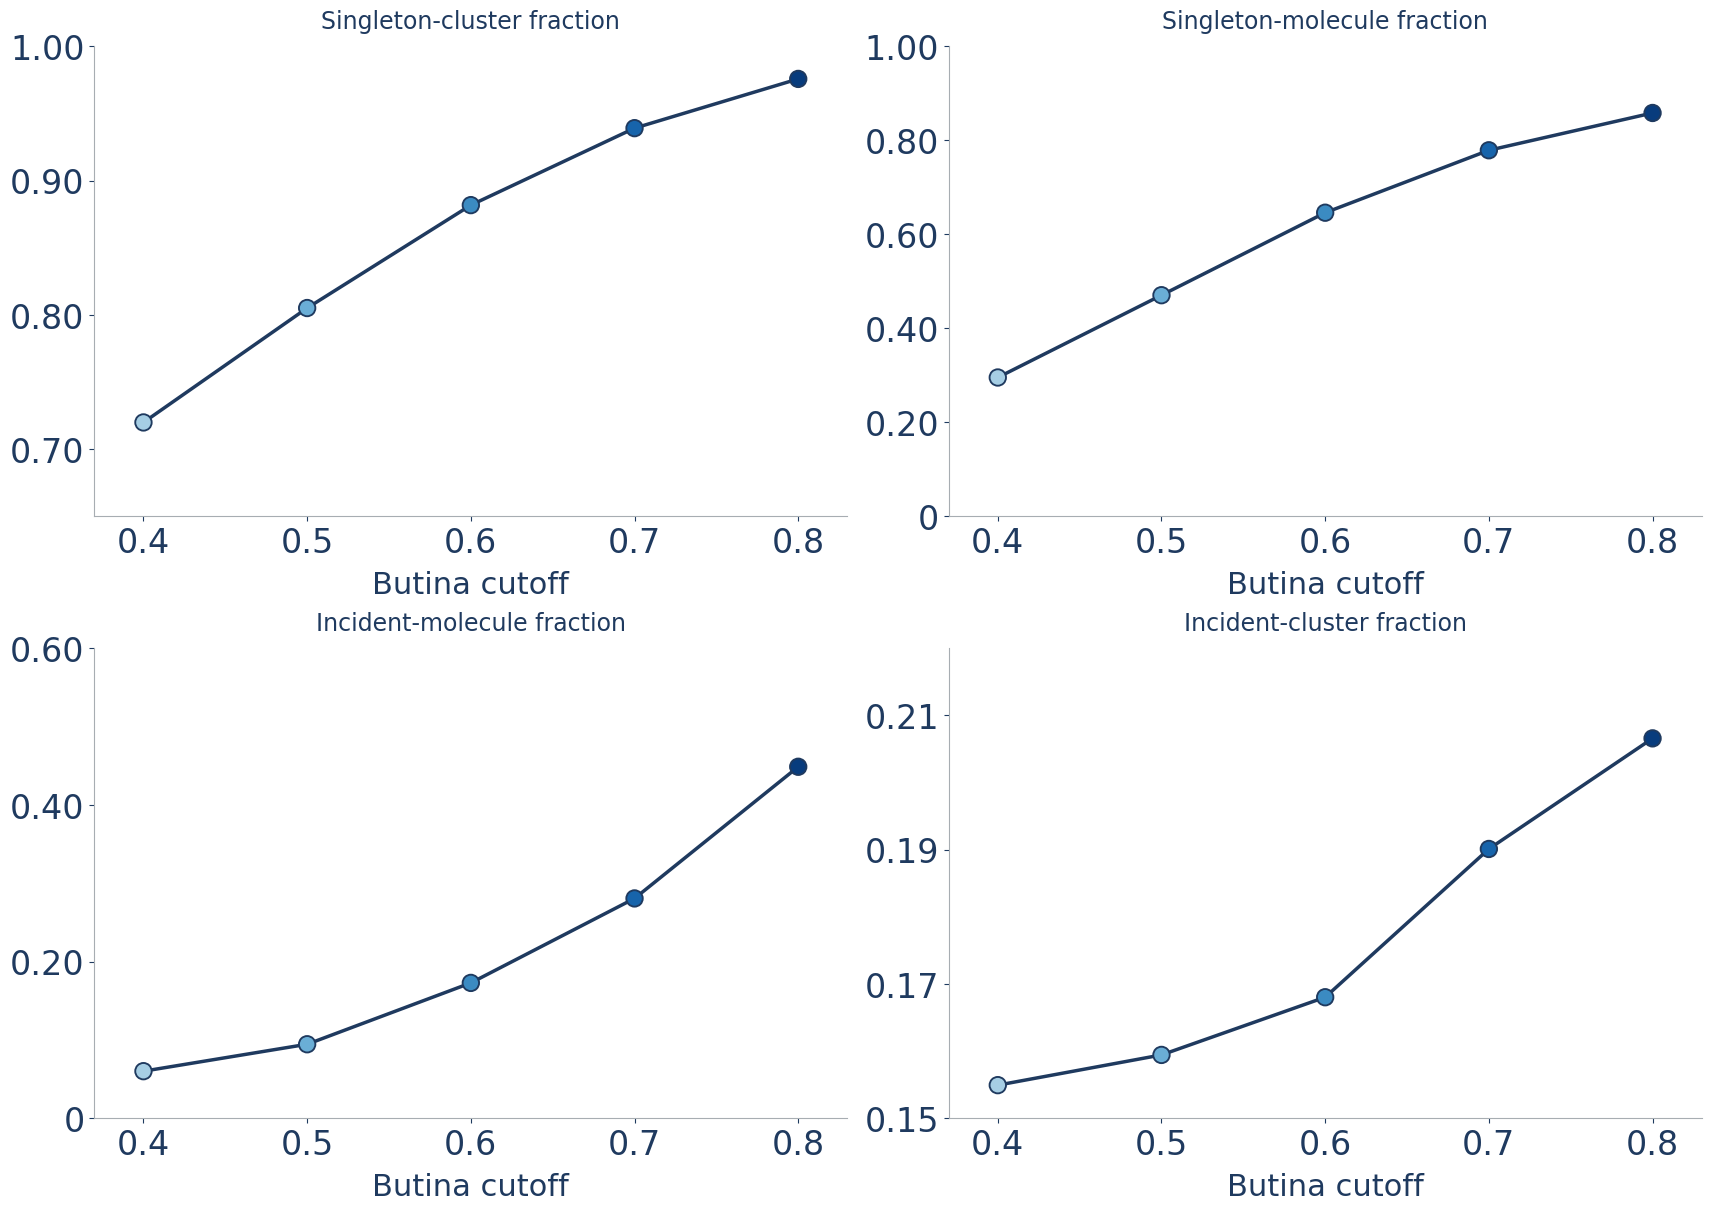

In [ ]:
# All four threshold-dependent fractions (original panels b–e).
fig_trends, axes_trends = plt.subplots(2, 2, figsize=(17, 12), constrained_layout=True)
trend_specs = [
    ('singleton_cluster_fraction', 'Singleton-cluster fraction',
     dict(fraction_axis_lower=0.65, omit_lower_fraction_tick=True)),
    ('singleton_molecule_fraction', 'Singleton-molecule fraction', {}),
    ('incident_eligible_molecule_fraction', 'Incident-molecule fraction', {}),
    ('incident_cluster_fraction', 'Incident-cluster fraction',
     dict(fraction_axis_lower=0.15, tight_fraction_top=True)),
]
for ax, (key, title, extra) in zip(axes_trends.flat, trend_specs):
    plot_threshold_single_trend(
        ax, thresholds, multi_stats[key], title, **extra,
    )
plt.show()


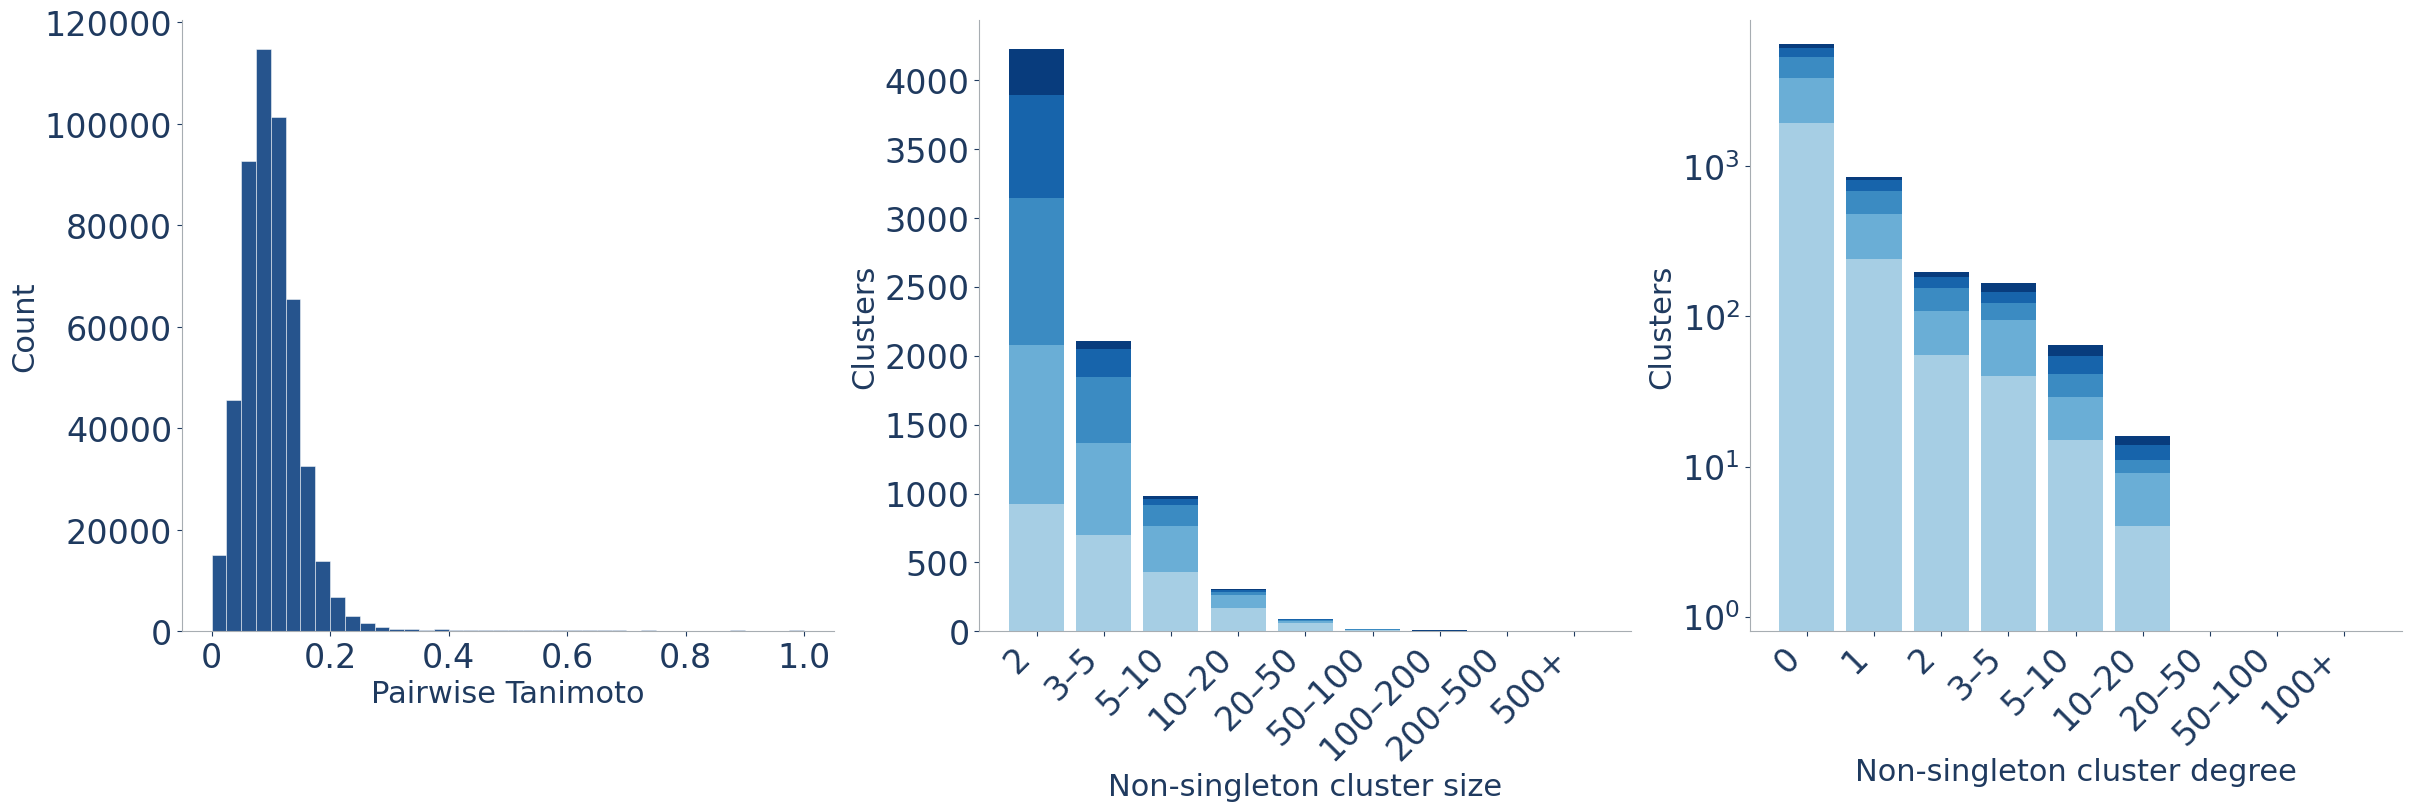

In [ ]:
# Sample similarity and the two cluster-level histogram panels.
fig_distributions, axes_distributions = plt.subplots(
    1, 3, figsize=(24, 8), constrained_layout=True,
)
plot_tanimoto_distribution(axes_distributions[0], tanimoto_values)
plot_stacked_metric_distribution_by_threshold(
    axes_distributions[1], thresholds, multi_stats['cluster_size_values'],
    'Non-singleton cluster size', 'Clusters', 'cluster_size',
    precomputed=metric_distributions['cluster_size'],
)
plot_stacked_metric_distribution_by_threshold(
    axes_distributions[2], thresholds, multi_stats['degree_values'],
    'Non-singleton cluster degree', 'Clusters', 'degree',
    precomputed=metric_distributions['degree'],
)
axes_distributions[2].set_yscale('log')
axes_distributions[2].set_ylim(bottom=0.8)
axes_distributions[2].yaxis.set_major_locator(LogLocator(base=10, numticks=7))
axes_distributions[2].yaxis.set_major_formatter(LogFormatterMathtext(base=10))
axes_distributions[2].yaxis.set_minor_locator(NullLocator())
plt.show()


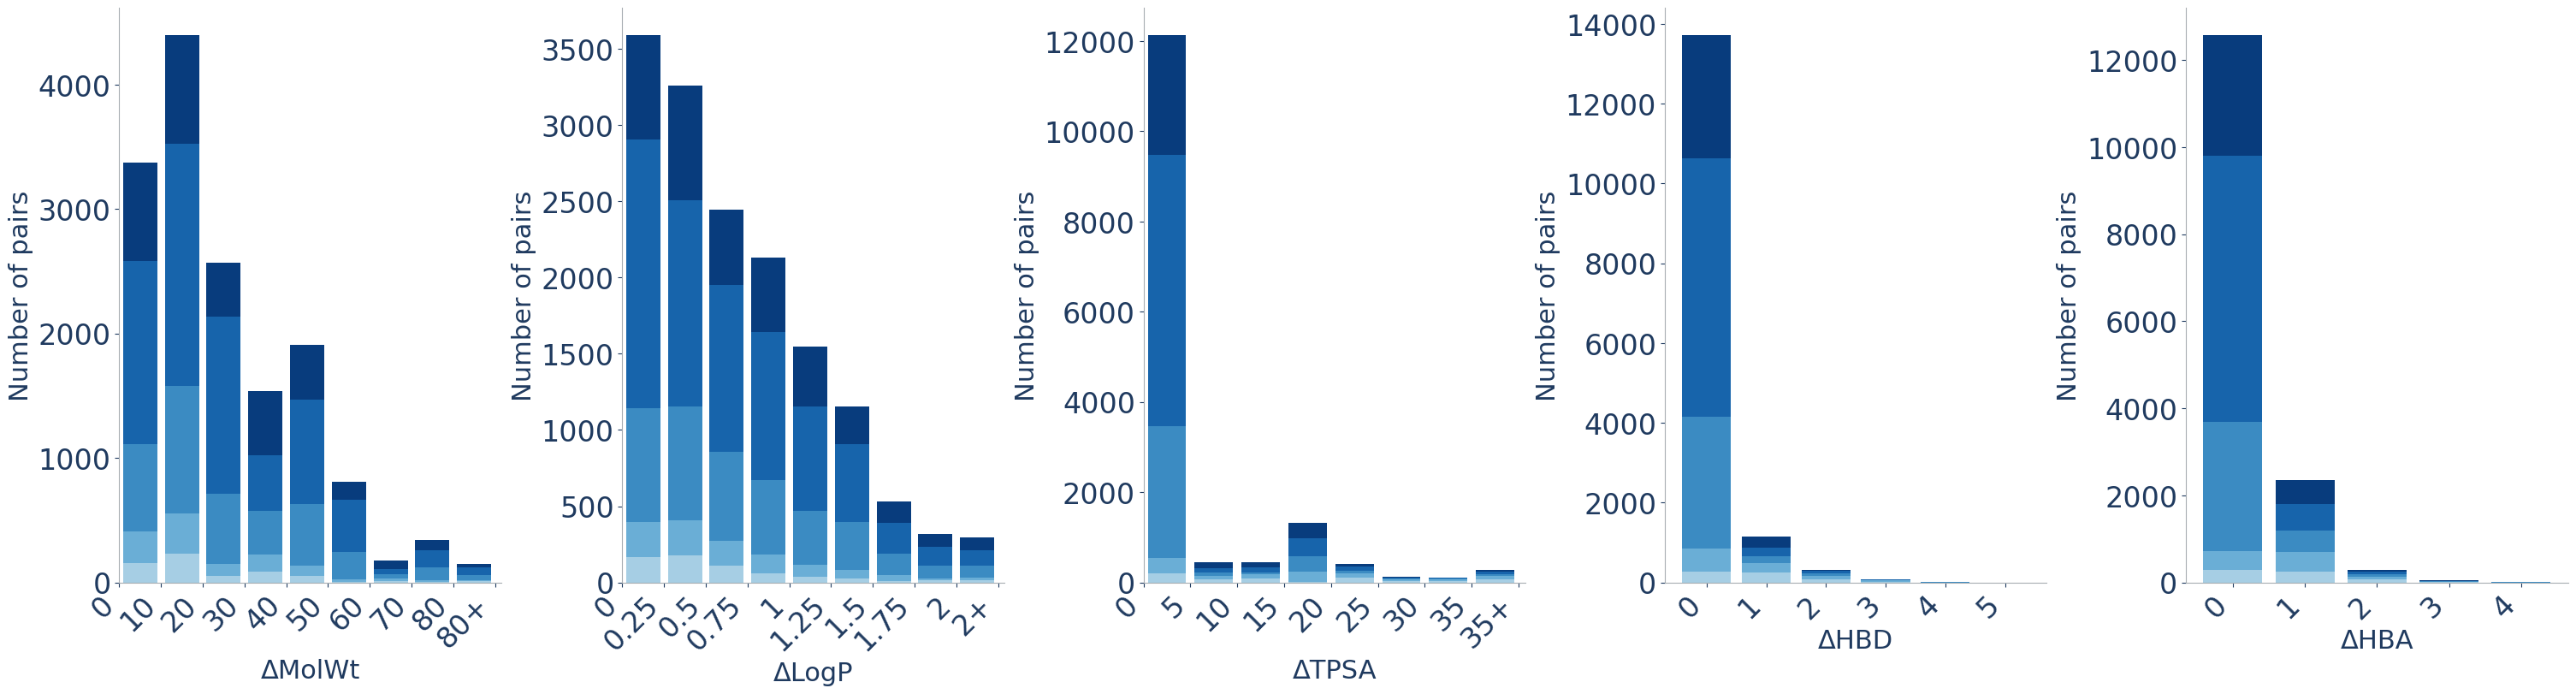

In [ ]:
# All five descriptor-delta histograms 
fig_deltas, axes_deltas = plt.subplots(
    1, len(PROPERTY_COLUMNS), figsize=(30, 8), constrained_layout=True,
)
for ax, prop in zip(axes_deltas, PROPERTY_COLUMNS):
    plot_stacked_metric_distribution_by_threshold(
        ax, thresholds, multi_stats['delta_values'][prop], f'Δ{prop}',
        'Number of pairs', 'delta', prop=prop,
        precomputed=metric_distributions[f'delta_{prop}'],
    )
plt.show()


## Full figure and exports

Saved final figure:
  butina_network_outputs/butina_network_0p40.png
  butina_network_outputs/butina_network_0p40.svg
  butina_network_outputs/butina_network_0p40.pdf


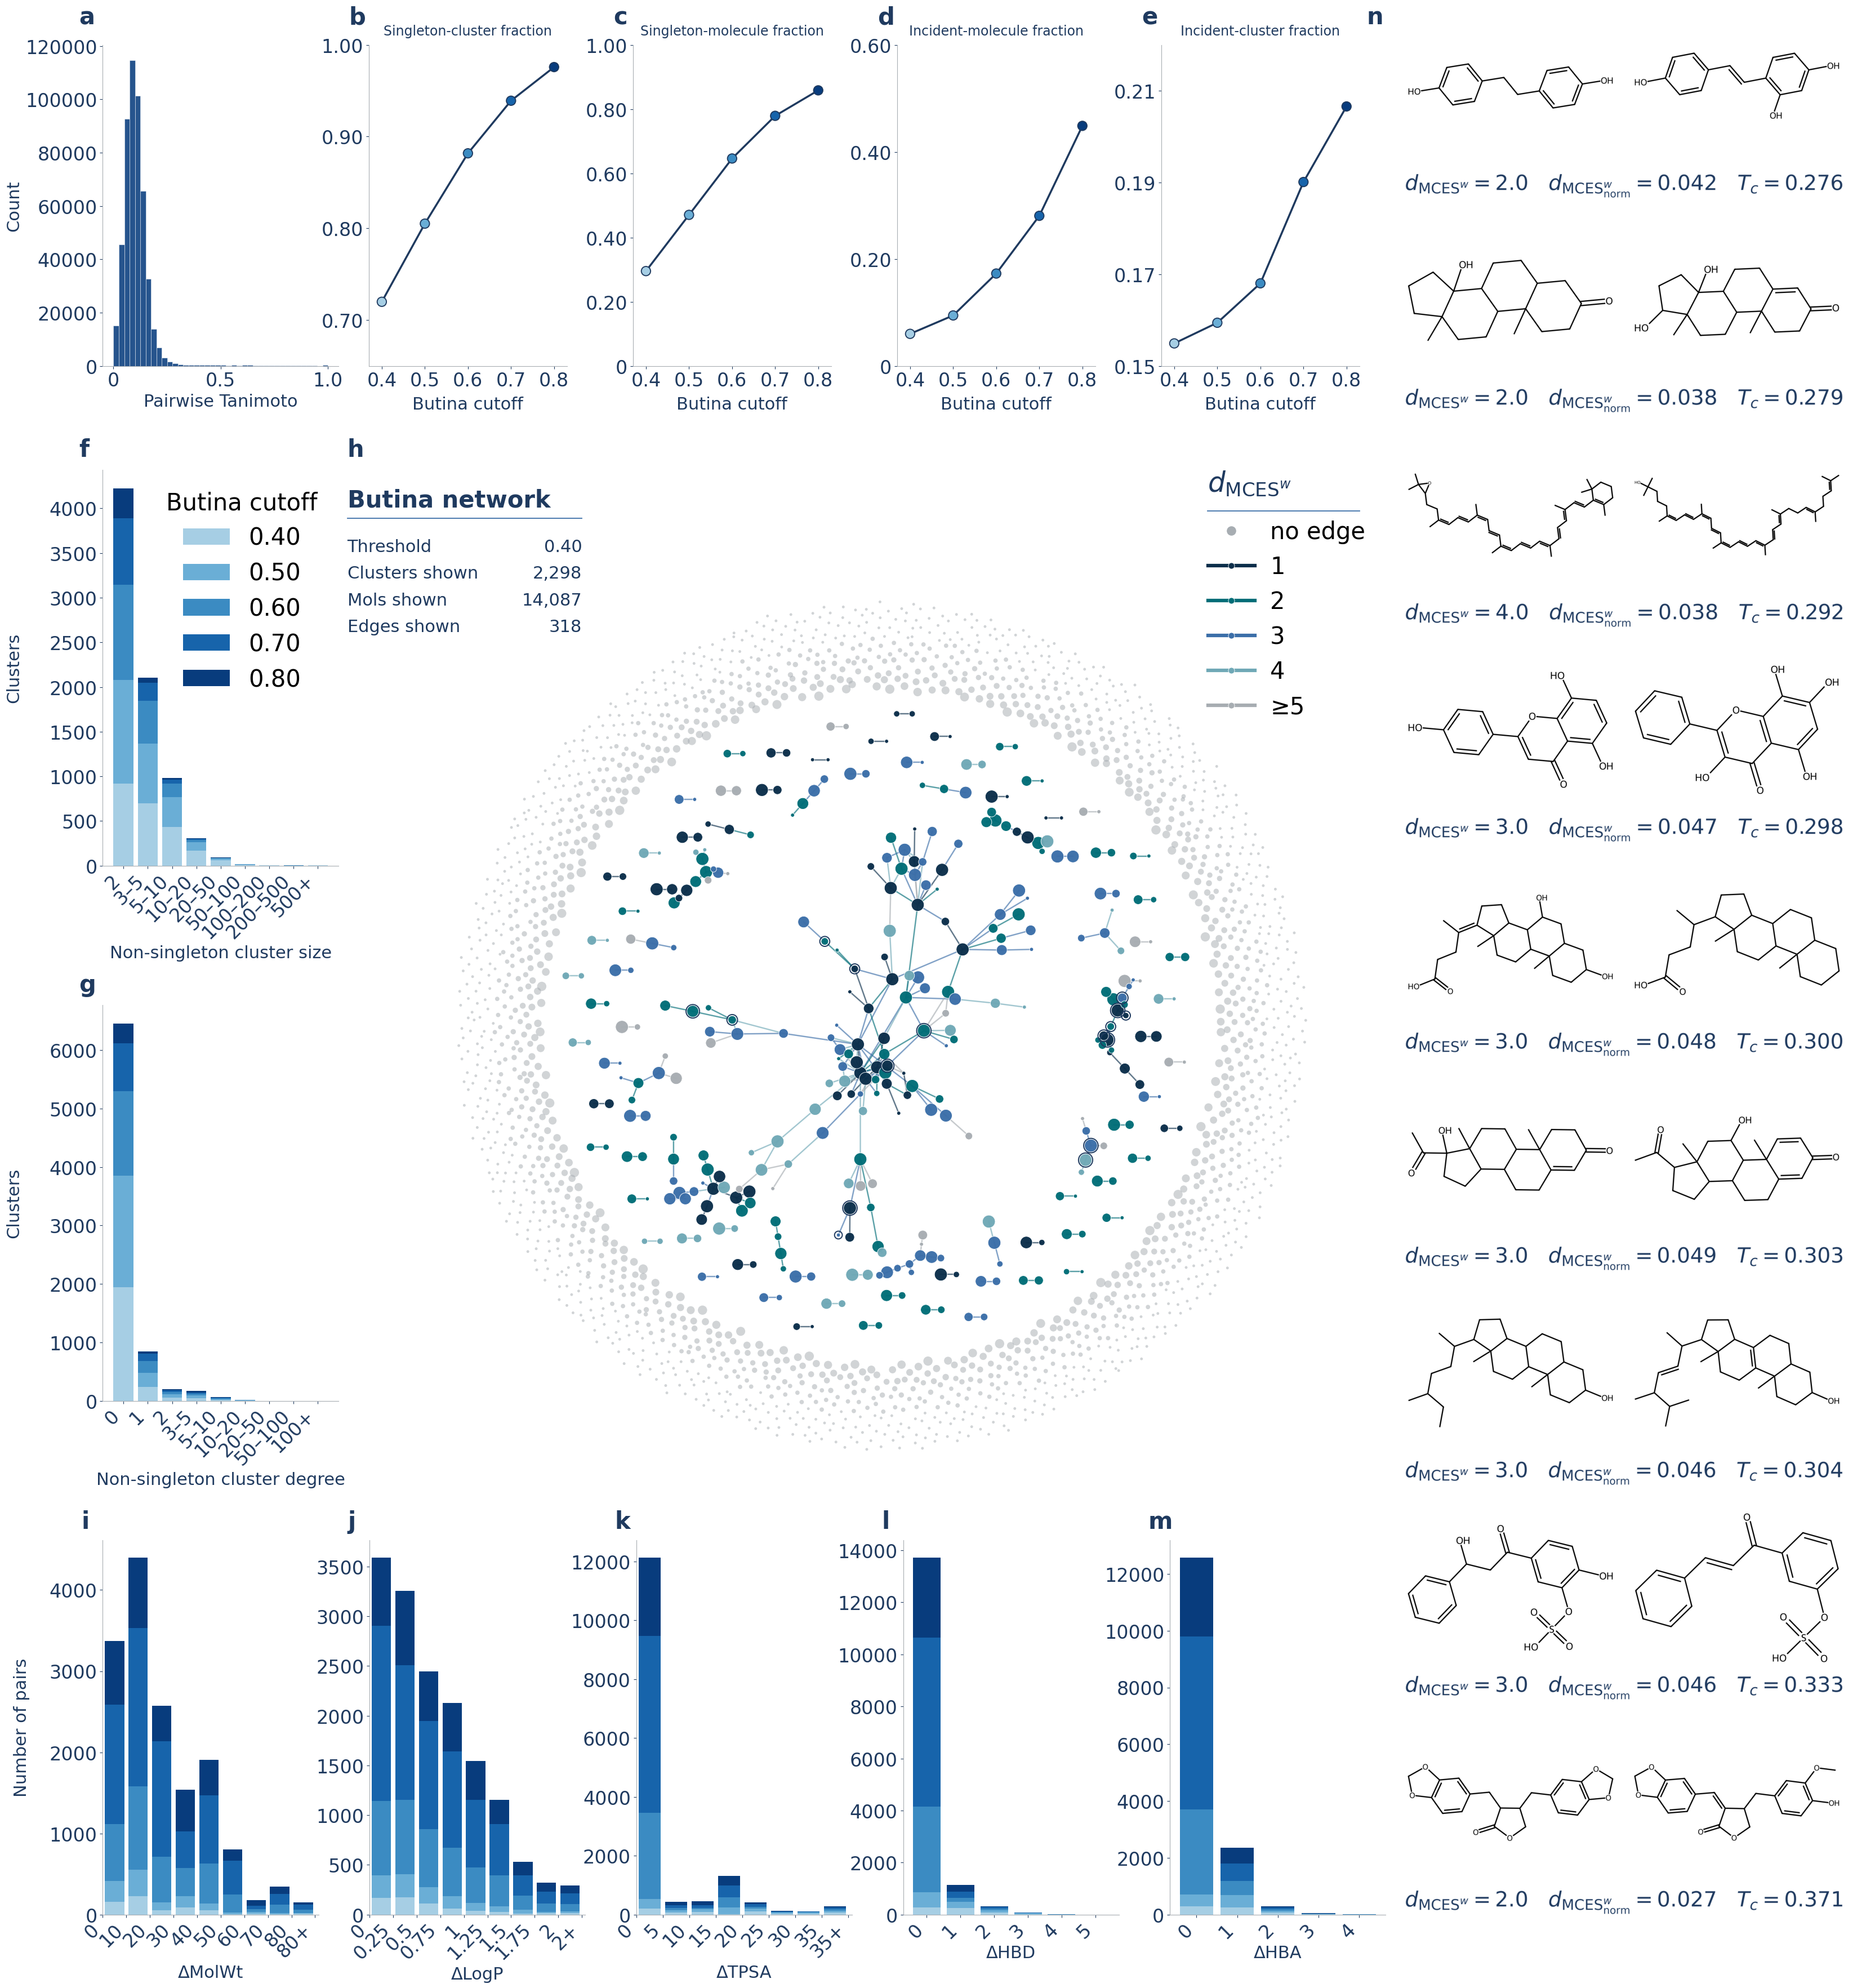

In [ ]:
# Assemble the full 14-panel figure.
fig = plot_full_figure(
    layout=layout, background_edges=background_edges, selected_edges=selected_edges,
    mols=mols, multi_stats=multi_stats, tanimoto_values=tanimoto_values,
    figsize=(33.5, 38), metric_distributions=metric_distributions,
)

png_path = os.path.join(OUTPUT_DIR, f'butina_network_{threshold_tag}.png')
svg_path = os.path.join(OUTPUT_DIR, f'butina_network_{threshold_tag}.svg')
pdf_path = os.path.join(OUTPUT_DIR, f'butina_network_{threshold_tag}.pdf')

fig.savefig(png_path, dpi=450, bbox_inches='tight', pad_inches=0.05)
fig.savefig(svg_path, bbox_inches='tight', pad_inches=0.05)
fig.savefig(pdf_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
print('Saved final figure:', png_path, svg_path, pdf_path, sep='\n  ')
plt.show()
